# LDA Lab — see every claim from the README with your own eyes

This notebook is the hands-on companion to [`../README.md`](../README.md).
Every lab is **self-contained**: a short goal, the code, the picture/numbers, and a
**"How to read this"** box that tells you what you should notice.

**How to use it**

1. Run the first code cell (imports and four small helper functions). After that you can run any lab in order
   (`Shift + Enter` cell by cell), or **Run All**. Labs only reuse data from *earlier* labs, so running
   top-to-bottom always works.
2. Read the "How to read this" box *after* looking at the output — try to guess first.
3. Change the numbers marked `# <- try changing this` and re-run to build intuition.
4. Proofs and longer explanations are hidden in collapsible cells (**click to expand**) right under a lab's heading.
   You can skip them and still follow every lab.

| Part | Labs | What it shows |
|---|---|---|
| **A. How LDA works** | 1 – 5 | Class means and scatter → Fisher's ratio → a generalised eigenproblem → at most C − 1 axes → the same answer from Gaussians |
| **B. Why LDA is useful in ML** | 6 – 11 | It keeps class separation (PCA keeps variance), squeezes many classes into few axes, is a strong simple classifier, survives p > n with shrinkage, ignores units |
| **C. Where LDA fails (and why)** | 12 – 16 | Label leakage, unequal class shapes, multimodal / curved classes, outliers, imbalanced classes |

All datasets are generated in the notebook or ship inside scikit-learn (iris, wine, breast_cancer, digits) —
**no internet needed**. Every random step uses a fixed seed, so you get the same numbers as the saved outputs.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from scipy.linalg import eigh
from scipy.stats import chi2

from sklearn.covariance import OAS, MinCovDet
from sklearn.datasets import load_breast_cancer, load_digits, load_iris, load_wine, make_moons
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, recall_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})


def direction(theta):
    """Unit vector pointing at angle `theta` (degrees)."""
    return np.array([np.cos(np.radians(theta)), np.sin(np.radians(theta))])


def angle_of(vector):
    """Direction of a 2-D vector in degrees, folded into [0, 180) because w and -w are the same axis."""
    return np.degrees(np.arctan2(vector[1], vector[0])) % 180


def scatter_matrices(X, y):
    """Within-class scatter Sw and between-class scatter Sb (sums, not divided by n)."""
    overall_mean = X.mean(axis=0)
    p = X.shape[1]
    Sw, Sb = np.zeros((p, p)), np.zeros((p, p))
    for k in np.unique(y):
        Xk = X[y == k]
        mk = Xk.mean(axis=0)
        Sw += (Xk - mk).T @ (Xk - mk)
        Sb += len(Xk) * np.outer(mk - overall_mean, mk - overall_mean)
    return Sw, Sb


def fisher_ratio(X, y, w):
    """Fisher's criterion J(w): between-class scatter / within-class scatter of the 1-D projection X @ w."""
    z = X @ w
    between = sum((y == k).sum() * (z[y == k].mean() - z.mean()) ** 2 for k in np.unique(y))
    within = sum(((z[y == k] - z[y == k].mean()) ** 2).sum() for k in np.unique(y))
    return between / within


def draw_arrow(ax, start, vector, color, label=None, lw=2.5):
    """Draw `vector` as an arrow starting at `start`; `label` goes into the legend."""
    ax.annotate("", xy=np.asarray(start) + vector, xytext=start,
                arrowprops=dict(arrowstyle="->", color=color, lw=lw))
    if label:
        ax.plot([], [], color=color, lw=lw, label=label)  # invisible line, only for the legend


def plot_regions(ax, model, X, y, title, xlabel="feature 1", ylabel="feature 2"):
    """Shade the classes `model` predicts over a grid, then scatter the points on top."""
    pad = 0.5
    g1, g2 = np.meshgrid(np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, 300),
                         np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, 300))
    regions = model.predict(np.c_[g1.ravel(), g2.ravel()]).reshape(g1.shape)
    ax.contourf(g1, g2, regions, alpha=0.2, cmap="coolwarm")
    ax.scatter(X[:, 0], X[:, 1], c=y, s=8, cmap="coolwarm")
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.set_title(title)

---
# Part A — How LDA works

## Lab 1 · The hand-worked example, done by the computer

**Goal:** reproduce README section 5 (“A small example worked by hand”) number by number:
six points in two classes → class means → within-class scatter $S_W$ → between-class scatter $S_B$ →
Fisher's direction $w = S_W^{-1}(m_1 - m_0)$ → Fisher's ratio $J$. Then compare it with the “obvious” direction,
the line that joins the two class means.

<details>
<summary><b>Explanation: what is $S_W^{-1}$, and how do you compute it for a 2 × 2 matrix? (click to expand)</b></summary>

**Symbols.** $I$ is the **identity matrix**, $\begin{pmatrix}1&0\\0&1\end{pmatrix}$: multiplying any vector by it
changes nothing. The **inverse** $A^{-1}$ of a square matrix $A$ is the matrix that undoes $A$:
$A^{-1}A = A A^{-1} = I$. It plays the role that $1/a$ plays for a number: $a \cdot (1/a) = 1$.

**The 2 × 2 formula.** For $A = \begin{pmatrix}a&b\\c&d\end{pmatrix}$, the number $\det A = ad - bc$ is its
**determinant**. If $\det A \ne 0$,

$$A^{-1} = \frac{1}{ad - bc}\begin{pmatrix}d & -b\\ -c & a\end{pmatrix}$$

(swap the diagonal, flip the signs of the other two, divide by the determinant). If $\det A = 0$ there is no inverse,
just as $1/0$ does not exist — Lab 10 is about exactly that situation.

**Our numbers.** $S_W = \begin{pmatrix}4&2\\2&4\end{pmatrix}$, so $\det S_W = 16 - 4 = 12$ and

$$S_W^{-1} = \frac{1}{12}\begin{pmatrix}4&-2\\-2&4\end{pmatrix},\qquad
S_W^{-1}(m_1 - m_0) = \frac{1}{12}\begin{pmatrix}4\cdot 3 - 2\cdot 1\\ -2\cdot 3 + 4\cdot 1\end{pmatrix}
= \frac{1}{12}\begin{pmatrix}10\\-2\end{pmatrix} = \frac{1}{6}\begin{pmatrix}5\\-1\end{pmatrix}$$

Only the **direction** of $w$ matters (lengthening the line does not change which points land where relative to each
other), so we may as well use the whole-number version $w = (5, -1)$.

**In code** you rarely form an inverse: `np.linalg.solve(Sw, m1 - m0)` finds the $w$ with $S_W w = m_1 - m_0$
directly, which is faster and more accurate.

</details>

In [2]:
X_toy = np.array([[1, 1], [2, 3], [3, 2],      # class 0
                  [4, 2], [5, 4], [6, 3]],     # class 1
                 dtype=float)
y_toy = np.array([0, 0, 0, 1, 1, 1])

m0, m1 = X_toy[y_toy == 0].mean(axis=0), X_toy[y_toy == 1].mean(axis=0)   # step 1: class means
Sw_toy, Sb_toy = scatter_matrices(X_toy, y_toy)                            # steps 2-3: scatter matrices

w_toy = np.linalg.solve(Sw_toy, m1 - m0)       # step 4: w = Sw^-1 (m1 - m0)  (solve() avoids forming the inverse)
eigenvalues_toy = eigh(Sb_toy, Sw_toy, eigvals_only=True)[::-1]            # same answer as an eigenproblem

print("class means          :", m0, m1, "  overall mean:", X_toy.mean(axis=0))
print("within-class scatter Sw:\n", Sw_toy)
print("between-class scatter Sb:\n", Sb_toy)
print("w = Sw^-1 (m1 - m0)  :", w_toy, " = (5, -1) /", 5 / w_toy[0])
print("generalised eigenvalues of (Sb, Sw):", eigenvalues_toy)
for name, w in [("Fisher's w (5, -1)", np.array([5.0, -1.0])), ("joining the means (3, 1)", m1 - m0)]:
    print(f"{name:26s}: projections {X_toy @ w}, J = {fisher_ratio(X_toy, y_toy, w):.3f}")

class means          : [2. 2.] [5. 3.]   overall mean: [3.5 2.5]
within-class scatter Sw:
 [[4. 2.]
 [2. 4.]]
between-class scatter Sb:
 [[13.5  4.5]
 [ 4.5  1.5]]
w = Sw^-1 (m1 - m0)  : [ 0.833 -0.167]  = (5, -1) / 6.0
generalised eigenvalues of (Sb, Sw): [3.5 0. ]
Fisher's w (5, -1)        : projections [ 4.  7. 13. 18. 21. 27.], J = 3.500
joining the means (3, 1)  : projections [ 4.  9. 11. 14. 19. 21.], J = 2.885


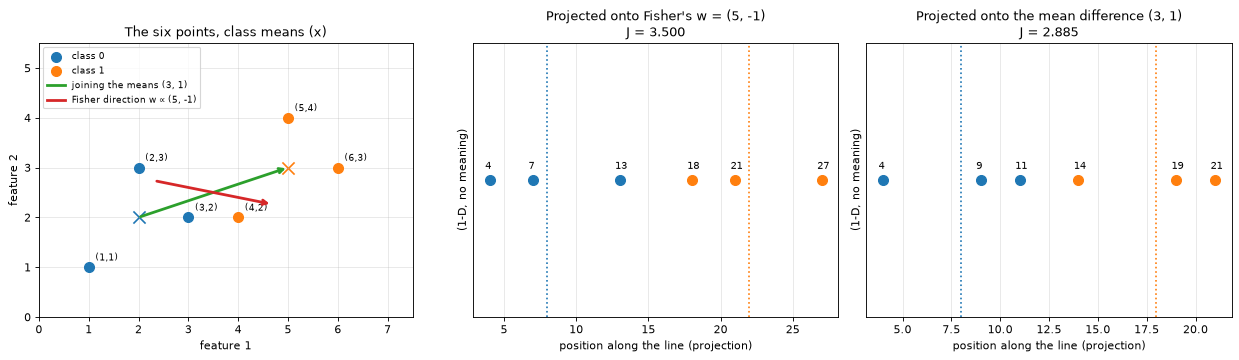

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1.2, 1, 1]})

ax = axes[0]
ax.scatter(*X_toy[y_toy == 0].T, s=80, color="tab:blue", label="class 0", zorder=3)
ax.scatter(*X_toy[y_toy == 1].T, s=80, color="tab:orange", label="class 1", zorder=3)
for (x1, x2) in X_toy:
    ax.annotate(f"({x1:.0f},{x2:.0f})", (x1, x2), textcoords="offset points", xytext=(6, 6), fontsize=8)
ax.scatter(*m0, marker="x", s=120, color="tab:blue"); ax.scatter(*m1, marker="x", s=120, color="tab:orange")
draw_arrow(ax, m0, m1 - m0, "tab:green", "joining the means (3, 1)")
draw_arrow(ax, X_toy.mean(axis=0) - 1.2 * w_toy / np.linalg.norm(w_toy), 2.4 * w_toy / np.linalg.norm(w_toy),
           "tab:red", "Fisher direction w ∝ (5, -1)")
ax.set_aspect("equal"); ax.set_xlim(0, 7.5); ax.set_ylim(0, 5.5)
ax.set_xlabel("feature 1"); ax.set_ylabel("feature 2"); ax.set_title("The six points, class means (x)")
ax.legend(loc="upper left", fontsize=8)

for ax, w, color, title in [(axes[1], np.array([5.0, -1.0]), "tab:red", "Projected onto Fisher's w = (5, -1)"),
                            (axes[2], np.array([3.0, 1.0]), "tab:green", "Projected onto the mean difference (3, 1)")]:
    z = X_toy @ w
    for k, c in [(0, "tab:blue"), (1, "tab:orange")]:
        ax.scatter(z[y_toy == k], np.zeros(3), s=80, color=c, zorder=3)
        ax.axvline(z[y_toy == k].mean(), color=c, ls=":")
        for v in z[y_toy == k]:
            ax.annotate(f"{v:.0f}", (v, 0), textcoords="offset points", xytext=(-4, 10), fontsize=9)
    ax.set_ylim(-1, 1); ax.set_yticks([])
    ax.set_xlabel("position along the line (projection)"); ax.set_ylabel("(1-D, no meaning)")
    ax.set_title(f"{title}\nJ = {fisher_ratio(X_toy, y_toy, w):.3f}")
plt.tight_layout(); plt.show()

> **How to read this**
> * The printout matches README section 5: class means $(2, 2)$ and $(5, 3)$,
>   $S_W = \begin{pmatrix}4&2\\2&4\end{pmatrix}$, $S_B = \begin{pmatrix}13.5&4.5\\4.5&1.5\end{pmatrix}$, and
>   $w = S_W^{-1}(m_1 - m_0) = (0.833, -0.167)$, which is $(5, -1)/6$.
> * **Middle plot:** projected onto $w = (5, -1)$, class 0 lands at 4, 7, 13 and class 1 at 18, 21, 27. The classes
>   do not overlap at all and $J = 3.500$.
> * **Right plot:** the “obvious” line joining the two means, $(3, 1)$, gives 4, 9, 11 and 14, 19, 21. Still separate,
>   but the gap between the groups (11 → 14) is small compared with their spread, so $J$ is only 2.885.
> * Why is the obvious line worse? Inside each class the points are tilted (feature 1 and feature 2 rise together).
>   Fisher's $w$ leans away from that tilt, so each class gets **squashed** on the line while the means stay far apart.
> * The generalised eigenvalues of $(S_B, S_W)$ are **3.5 and 0**: the top one is exactly the best possible $J$.
>   Lab 2 explains why.

## Lab 2 · Try every direction: Fisher's ratio and the eigenvector

**Goal:** forget the formula and **brute-force** it. Two classes share the same tilted, cigar-shaped spread. For 360
candidate directions (every 0.5° from 0° to 180°) we project all 300 points onto the line and compute Fisher's ratio

$$J(w) = \frac{\text{between-class scatter of the projections}}{\text{within-class scatter of the projections}}$$

Big $J$ = the class centres land far apart **and** each class lands in a tight bunch. Claim: the best direction is
the top eigenvector of the generalised eigenproblem $S_B w = \lambda S_W w$, the best $J$ equals the top eigenvalue,
and the **worst** direction gives $J = 0$.

The proof is in the collapsed cell below; the code after it checks the claim by brute force.

<details>
<summary><b>Proof: why maximising Fisher's ratio gives the eigenproblem $S_B w = \lambda S_W w$ (click to expand)</b></summary>

**Symbols.** There are $C$ classes. Class $k$ has $n_k$ points, mean $m_k$; $m$ is the mean of all $n$ points.
$w$ is the direction we project onto, a column vector; $w^\top$ is the same numbers written as a row (the
**transpose**), so $w^\top x = w_1 x_1 + w_2 x_2 + \dots$ is the projection (“shadow position”) of point $x$.
$\sum_{i \in k}$ means “add up over the points of class $k$”.

$$S_W = \sum_{k=1}^{C} \sum_{i \in k} (x_i - m_k)(x_i - m_k)^\top \qquad
S_B = \sum_{k=1}^{C} n_k\, (m_k - m)(m_k - m)^\top$$

Both are $p \times p$ symmetric matrices. $S_W$ measures how spread out each class is around its **own** centre;
$S_B$ measures how spread out the class **centres** are around the overall centre.

**Step 1: the two scatters of the projections are $w^\top S_B w$ and $w^\top S_W w$.**
A projected class mean is $w^\top m_k$. For any vector $a$, $(w^\top a)^2 = (w^\top a)(a^\top w) = w^\top (a a^\top) w$.
So

$$\sum_k n_k (w^\top m_k - w^\top m)^2 = w^\top \Big[\sum_k n_k (m_k - m)(m_k - m)^\top\Big] w = w^\top S_B\, w$$

and in the same way $\sum_k \sum_{i \in k} (w^\top x_i - w^\top m_k)^2 = w^\top S_W w$. Therefore

$$J(w) = \frac{w^\top S_B\, w}{w^\top S_W\, w}$$

**Step 2: only the direction matters.** Replacing $w$ by $c\,w$ multiplies top and bottom by $c^2$, so $J$ does not
change. We may therefore fix the bottom, $w^\top S_W w = 1$, and maximise the top.

**Step 3: the eigenproblem appears (calculus route).** Maximise $w^\top S_B w - \lambda\,(w^\top S_W w - 1)$, where
$\lambda$ is a Lagrange multiplier (a helper number that enforces the constraint). The derivative with respect to
$w$ is $2 S_B w - 2 \lambda S_W w$; setting it to zero gives

$$S_B\, w = \lambda\, S_W\, w$$

the **generalised eigenproblem**. Multiply both sides by $w^\top$ on the left:
$w^\top S_B w = \lambda\, w^\top S_W w$, i.e. $J(w) = \lambda$. Every solution is a candidate and its $J$ is its
eigenvalue, so the best direction is the eigenvector with the **largest** eigenvalue.

*Calculus-free route.* Change coordinates so that $S_W$ becomes the identity (“whitening”: stretch the space until
every class looks round). In those coordinates $J = \dfrac{v^\top M v}{v^\top v}$ for a symmetric matrix $M$, which
is exactly the PCA problem: by the weighted-average argument in the PCA lab (Lab 3), its maximum is the top eigenvalue
of $M$. Undoing the change of coordinates turns the eigenvectors of $M$ into the solutions of $S_B w = \lambda S_W w$.

**Step 4: two classes have a closed form.** With $C = 2$, $m_k - m$ is a multiple of $m_1 - m_0$ for both classes,
and $S_B = \frac{n_0 n_1}{n}(m_1 - m_0)(m_1 - m_0)^\top$. So $S_B w = \frac{n_0 n_1}{n}(m_1 - m_0)\,[(m_1 - m_0)^\top w]$
always points along $m_1 - m_0$. The eigen-equation then says $S_W w$ points along $m_1 - m_0$, i.e.

$$w \;\propto\; S_W^{-1}(m_1 - m_0)$$

($\propto$ means “points the same way as”). That is the formula used in Lab 1.

**Step 5: the worst direction has $J = 0$.** If $w$ is at right angles to $m_1 - m_0$, then $w^\top(m_1 - m_0) = 0$:
both class centres cast their shadow on the **same** spot, the top of $J$ is 0, and so is $J$. The second eigenvalue
for two classes is therefore always 0.

</details>

In [4]:
rng = np.random.default_rng(0)
shared_cov = [[3.0, 2.0], [2.0, 2.0]]                       # both classes have this shape   <- try changing this
X_bf = np.vstack([rng.multivariate_normal([0.0, 0.0], shared_cov, size=150),
                  rng.multivariate_normal([1.5, -0.5], shared_cov, size=150)])   # <- try moving the 2nd mean
y_bf = np.repeat([0, 1], 150)

thetas = np.arange(0, 180, 0.5)                             # 360 candidate directions, 0.5° apart
ratios = np.array([fisher_ratio(X_bf, y_bf, direction(t)) for t in thetas])

Sw_bf, Sb_bf = scatter_matrices(X_bf, y_bf)
eigenvalues_bf, eigenvectors_bf = eigh(Sb_bf, Sw_bf)        # generalised eigenproblem, ascending order
w_bf = eigenvectors_bf[:, -1]                               # top eigenvector = Fisher direction
mean_gap = X_bf[y_bf == 1].mean(axis=0) - X_bf[y_bf == 0].mean(axis=0)

print(f"brute force : best J = {ratios.max():.3f} at θ = {thetas[ratios.argmax()]:.1f}°,"
      f"  worst J = {ratios.min():.4f} at θ = {thetas[ratios.argmin()]:.1f}°")
print(f"eigenvector : top eigenvalue = {eigenvalues_bf[-1]:.3f} at θ = {angle_of(w_bf):.1f}°,"
      f"  other eigenvalue = {eigenvalues_bf[0]:.4f}")
print(f"closed form : Sw^-1 (m1 - m0) points at θ = {angle_of(np.linalg.solve(Sw_bf, mean_gap)):.1f}°")
print(f"joining the means points at θ = {angle_of(mean_gap):.1f}°, J = {fisher_ratio(X_bf, y_bf, mean_gap):.3f}")
print(f"at right angles to the mean gap: θ = {(angle_of(mean_gap) + 90) % 180:.1f}°  (projected means coincide -> J = 0)")

brute force : best J = 1.141 at θ = 129.5°,  worst J = 0.0000 at θ = 59.0°
eigenvector : top eigenvalue = 1.141 at θ = 129.7°,  other eigenvalue = 0.0000
closed form : Sw^-1 (m1 - m0) points at θ = 129.7°
joining the means points at θ = 149.1°, J = 0.563
at right angles to the mean gap: θ = 59.1°  (projected means coincide -> J = 0)


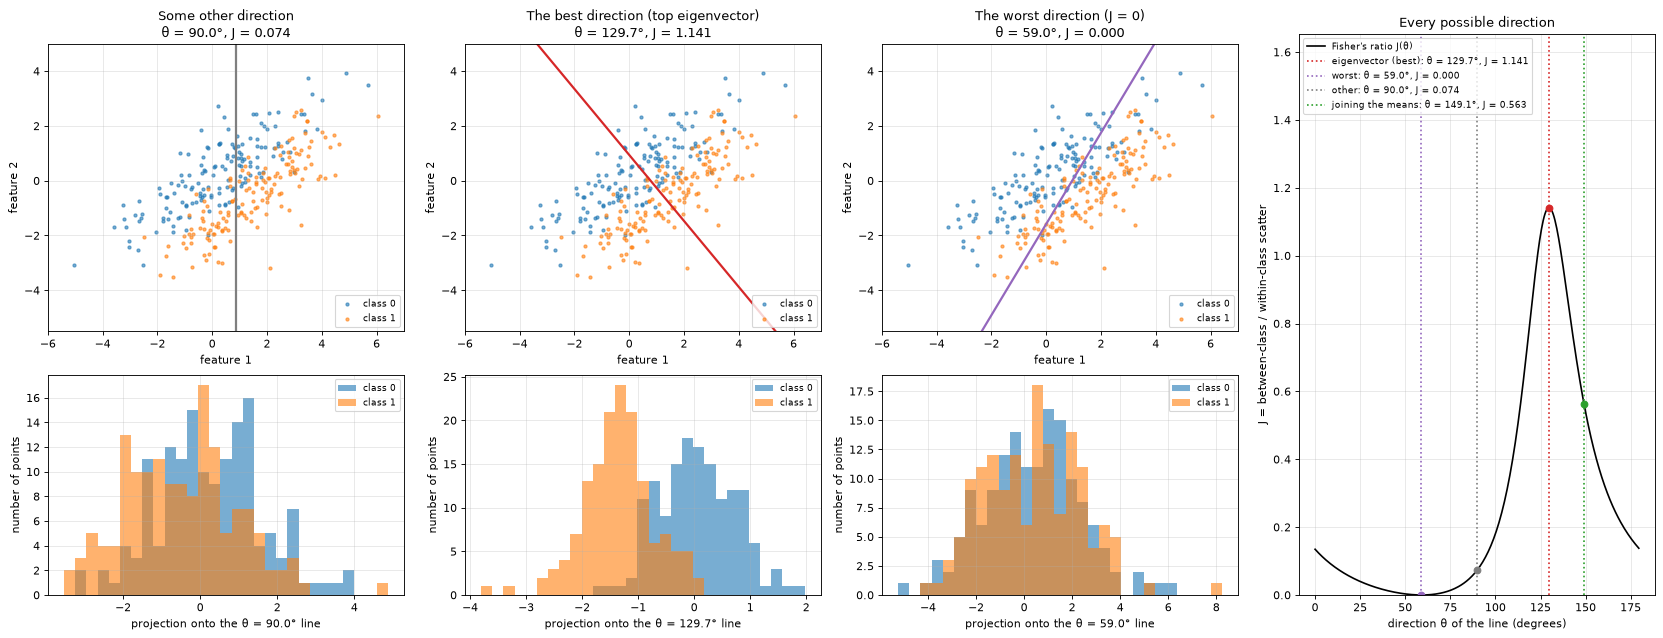

In [5]:
other_theta = 90                                            # <- try changing this
panels = [(direction(other_theta), "Some other direction", "tab:gray"),
          (w_bf, "The best direction (top eigenvector)", "tab:red"),
          (direction(thetas[ratios.argmin()]), "The worst direction (J = 0)", "tab:purple")]

fig = plt.figure(figsize=(21, 8))
grid = GridSpec(2, 4, figure=fig, height_ratios=[1.4, 1])
for col, (w, title, color) in enumerate(panels):
    w = w / np.linalg.norm(w)
    ax = fig.add_subplot(grid[0, col])
    ax.scatter(*X_bf[y_bf == 0].T, s=8, alpha=0.6, color="tab:blue", label="class 0")
    ax.scatter(*X_bf[y_bf == 1].T, s=8, alpha=0.6, color="tab:orange", label="class 1")
    ax.axline(X_bf.mean(axis=0), X_bf.mean(axis=0) + w, color=color, lw=2)
    ax.set_aspect("equal"); ax.set_xlim(-6, 7); ax.set_ylim(-5.5, 5)
    ax.set_xlabel("feature 1"); ax.set_ylabel("feature 2"); ax.legend(loc="lower right", fontsize=8)
    ax.set_title(f"{title}\nθ = {angle_of(w):.1f}°, J = {fisher_ratio(X_bf, y_bf, w):.3f}")

    ax = fig.add_subplot(grid[1, col])
    z = X_bf @ w
    bins = np.linspace(z.min(), z.max(), 30)
    ax.hist(z[y_bf == 0], bins=bins, alpha=0.6, color="tab:blue", label="class 0")
    ax.hist(z[y_bf == 1], bins=bins, alpha=0.6, color="tab:orange", label="class 1")
    ax.set_xlabel(f"projection onto the θ = {angle_of(w):.1f}° line"); ax.set_ylabel("number of points")
    ax.legend(fontsize=8)

ax = fig.add_subplot(grid[:, 3])
ax.plot(thetas, ratios, color="black", label="Fisher's ratio J(θ)")
for theta, color, name in [(angle_of(w_bf), "tab:red", "eigenvector (best)"),
                           (thetas[ratios.argmin()], "tab:purple", "worst"),
                           (other_theta, "tab:gray", "other"),
                           (angle_of(mean_gap), "tab:green", "joining the means")]:
    J = fisher_ratio(X_bf, y_bf, direction(theta))
    ax.axvline(theta, color=color, ls=":", label=f"{name}: θ = {theta:.1f}°, J = {J:.3f}")
    ax.plot(theta, J, "o", color=color)
ax.set_xlabel("direction θ of the line (degrees)"); ax.set_ylabel("J = between-class / within-class scatter")
ax.set_title("Every possible direction"); ax.legend(fontsize=8, loc="upper left")
ax.set_ylim(0, ratios.max() * 1.45)
plt.tight_layout(); plt.show()

> **How to read this**
> * **Brute force and linear algebra agree.** Trying all 360 angles finds the best $J = 1.141$ at 129.5°; the top
>   eigenvector points at 129.7° with eigenvalue 1.141 (the grid is 0.5° wide, so 129.5° is the closest grid angle).
>   The two-class shortcut $S_W^{-1}(m_1 - m_0)$ also gives 129.7°.
> * **Top row:** the coloured line is the line we project **onto** (where the shadows land), not a boundary. The class
>   boundary would sit at right angles to it (Lab 5).
> * **Bottom row:** the projections. On the best line (red, middle) the two histograms are mostly apart. On the worst
>   line (purple, 59.0°) they sit right on top of each other: $J = 0.000$, because this line is at right angles to
>   the gap between the class means (59.1°), so both centres land in the same place. The 90° line (grey) is in
>   between, $J = 0.074$. Change `other_theta` to try more.
> * **Right:** $J$ over every direction. It has one peak (the red dotted eigenvector line) and touches 0 once (purple).
> * The green dotted line is the “obvious” direction, joining the class means (149.1°). It gets $J = 0.563$, about
>   half the best. Both classes are tilted the same way, and the best line leans away from that tilt so that each
>   class looks thin. This is why LDA needs $S_W$, not just the means.
> * The second eigenvalue is 0.0000, as Step 5 of the proof predicts for two classes.

## Lab 3 · Three ways to solve the eigenproblem give the same answer (iris)

**Goal:** on the iris flowers (150 flowers, 4 measurements, 3 species) compute the LDA directions three ways:

1. turn $S_B w = \lambda S_W w$ into an ordinary eigenproblem of $S_W^{-1} S_B$,
2. solve the generalised eigenproblem directly with `scipy.linalg.eigh(Sb, Sw)`,
3. ask scikit-learn (`LinearDiscriminantAnalysis(solver="eigen")`).

Then check two side facts: the LDA scores are **uncorrelated inside each class**, but the LDA axes are **not at right
angles** to each other (unlike PCA).

<details>
<summary><b>Explanation: what is a generalised eigenproblem, and why are LDA axes not at right angles? (click to expand)</b></summary>

**Ordinary vs generalised.** An ordinary eigenproblem asks for directions $u$ that a matrix $A$ only stretches:
$A u = \lambda u$ (PCA solves this for the covariance matrix). A **generalised** eigenproblem involves two matrices:

$$A\, u = \lambda\, B\, u$$

“find directions where applying $A$ gives the same result as applying $B$, up to a stretch factor $\lambda$”.
LDA has $A = S_B$ and $B = S_W$.

**Turning it into an ordinary one.** If $B$ has an inverse, multiply both sides by $B^{-1}$:
$B^{-1} A\, u = \lambda u$. That is way 1 in the code. It works, but $B^{-1}A = S_W^{-1}S_B$ is **not symmetric**
even though $S_W$ and $S_B$ are, and computing with non-symmetric matrices is less accurate (`np.linalg.eig` can even
return tiny imaginary parts that must be thrown away).

**The stable way.** `scipy.linalg.eigh(A, B)` (way 2) needs $A$ symmetric and $B$ symmetric with all eigenvalues
$> 0$. It factors $B = L L^\top$ (a *Cholesky* factorisation, $L$ lower-triangular), rewrites the problem as the
symmetric ordinary problem $L^{-1} A L^{-\top} v = \lambda v$, solves that, and maps back with $u = L^{-\top} v$.
This is the “whitening” route from the Lab 2 proof. scikit-learn's default `svd` solver goes one step further and
never builds $S_W$ at all; it works on the (whitened) data with a singular value decomposition, which is the most
accurate option and also works when $S_W$ has no inverse.

**Why the scores are uncorrelated within classes.** Take two eigenvectors $w_i, w_j$ with different eigenvalues
$\lambda_i \ne \lambda_j$. Then $w_j^\top S_B w_i = \lambda_i\, w_j^\top S_W w_i$ and
$w_i^\top S_B w_j = \lambda_j\, w_i^\top S_W w_j$. Both matrices are symmetric, so the two left sides are equal and
$w_j^\top S_W w_i = w_i^\top S_W w_j$. Subtracting: $(\lambda_i - \lambda_j)\, w_i^\top S_W w_j = 0$, so
$w_i^\top S_W w_j = 0$. But $w_i^\top S_W w_j$ is (up to dividing by $n$) the **within-class covariance** of the two
score columns. So LD1 and LD2 scores are uncorrelated inside each class.

**Why the axes are not at right angles.** Right angles would need $w_i^\top w_j = 0$. The argument above gives
$w_i^\top S_W w_j = 0$ instead — “at right angles *after* whitening”. Unless $S_W$ is a multiple of $I$, those are
different conditions. PCA's axes are perpendicular because PCA's matrix is symmetric; $S_W^{-1}S_B$ is not.

</details>

In [6]:
X_iris, y_iris = load_iris(return_X_y=True)
Sw_iris, Sb_iris = scatter_matrices(X_iris, y_iris)

# Way 1: turn it into an ordinary eigenproblem of Sw^-1 Sb (fine for small, well-behaved data)
values_1, vectors_1 = np.linalg.eig(np.linalg.solve(Sw_iris, Sb_iris))
order = np.argsort(values_1.real)[::-1]
values_1, vectors_1 = values_1.real[order], vectors_1.real[:, order]

# Way 2: solve the generalised eigenproblem Sb w = λ Sw w directly (symmetric, numerically stable)
values_2, vectors_2 = eigh(Sb_iris, Sw_iris)
values_2, vectors_2 = values_2[::-1], vectors_2[:, ::-1]

# Way 3: scikit-learn
lda_iris = LinearDiscriminantAnalysis(solver="eigen").fit(X_iris, y_iris)

print("eigenvalues, way 1 (eig of Sw^-1 Sb):", values_1)
print("eigenvalues, way 2 (eigh(Sb, Sw))   :", values_2)
print("share of the total, ways 1/2        :", values_2[:2] / values_2.sum())
print("sklearn explained_variance_ratio_   :", lda_iris.explained_variance_ratio_)

def same_axis(a, b):
    """|cosine| between two directions: 1.000 means the same axis (length and sign don't matter)."""
    return abs(a @ b) / (np.linalg.norm(a) * np.linalg.norm(b))

for j in range(2):
    print(f"LD{j + 1}: |cos(way1, way2)| = {same_axis(vectors_1[:, j], vectors_2[:, j]):.6f},"
          f"  |cos(way2, sklearn)| = {same_axis(vectors_2[:, j], lda_iris.scalings_[:, j]):.6f}")

eigenvalues, way 1 (eig of Sw^-1 Sb): [32.192  0.285 -0.    -0.   ]
eigenvalues, way 2 (eigh(Sb, Sw))   : [32.192  0.285  0.    -0.   ]
share of the total, ways 1/2        : [0.991 0.009]
sklearn explained_variance_ratio_   : [0.991 0.009]
LD1: |cos(way1, way2)| = 1.000000,  |cos(way2, sklearn)| = 1.000000
LD2: |cos(way1, way2)| = 1.000000,  |cos(way2, sklearn)| = 1.000000


within-class correlation, petal length vs petal width (raw): 0.484
within-class correlation, LD1 vs LD2 scores               : -0.000
|cos| between LD1 and LD2 in feature space                : 0.176   <- not 0: LDA axes are NOT at right angles


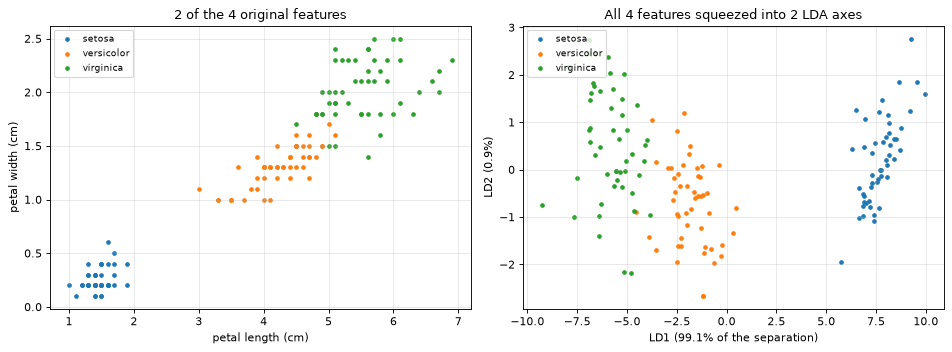

In [7]:
Z_iris = LinearDiscriminantAnalysis(n_components=2).fit_transform(X_iris, y_iris)   # default solver = "svd"

within_corr = np.corrcoef(np.vstack([Z_iris[y_iris == k] - Z_iris[y_iris == k].mean(axis=0)
                                     for k in range(3)]).T)[0, 1]
raw_within_corr = np.corrcoef(np.vstack([X_iris[y_iris == k] - X_iris[y_iris == k].mean(axis=0)
                                         for k in range(3)]).T)[2, 3]
print(f"within-class correlation, petal length vs petal width (raw): {raw_within_corr:.3f}")
print(f"within-class correlation, LD1 vs LD2 scores               : {within_corr:.3f}")
print(f"|cos| between LD1 and LD2 in feature space                : {same_axis(vectors_2[:, 0], vectors_2[:, 1]):.3f}"
      "   <- not 0: LDA axes are NOT at right angles")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
names = load_iris().target_names
for k, c in zip(range(3), ["tab:blue", "tab:orange", "tab:green"]):
    axes[0].scatter(X_iris[y_iris == k, 2], X_iris[y_iris == k, 3], s=10, color=c, label=names[k])
    axes[1].scatter(Z_iris[y_iris == k, 0], Z_iris[y_iris == k, 1], s=10, color=c, label=names[k])
axes[0].set_xlabel("petal length (cm)"); axes[0].set_ylabel("petal width (cm)")
axes[0].set_title("2 of the 4 original features")
axes[1].set_xlabel(f"LD1 ({lda_iris.explained_variance_ratio_[0]:.1%} of the separation)")
axes[1].set_ylabel(f"LD2 ({lda_iris.explained_variance_ratio_[1]:.1%})")
axes[1].set_title("All 4 features squeezed into 2 LDA axes")
for ax in axes:
    ax.legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

> **How to read this**
> * All three ways give the same eigenvalues, **32.192 and 0.285**, and the same directions ($|\cos| = 1.000000$
>   means “same axis”; the length and sign of an eigenvector are arbitrary).
> * The other two eigenvalues are 0 (printed as `0.` or `-0.`, round-off): iris has 3 classes, so at most
>   $C - 1 = 2$ directions separate anything. Lab 4 is about this.
> * `explained_variance_ratio_` is each eigenvalue's share: **0.991 and 0.009**. Despite its name, for LDA it is the
>   share of the **class separation**, not of the variance. LD1 alone does 99.1 % of the work.
> * Inside each species, petal length and petal width are correlated (0.484). The LD1 and LD2 scores are not (−0.000):
>   LDA axes carry no repeated within-class information.
> * Yet the two LDA axes are **not** perpendicular in the original 4-D space: $|\cos| = 0.176$, not 0.
> * Plot: on the right, LD1 alone pulls setosa far from the other two and nearly splits versicolor from virginica.

## Lab 4 · At most C − 1 components

**Goal:** see the hard limit on how many LDA axes exist. Digits has $C = 10$ classes and 61 pixels that vary
(3 border pixels are always 0, so we drop them). LDA can give at most $C - 1 = 9$ useful axes, no matter how many
features there are. Then watch scikit-learn refuse to give 3 axes for wine (3 classes).

<details>
<summary><b>Proof: why $S_B$ has at most $C - 1$ non-zero eigenvalues (click to expand)</b></summary>

**Symbols.** The **rank** of a matrix is the number of independent directions it can produce; for a symmetric matrix
like $S_B$ it is the number of non-zero eigenvalues. $a\,a^\top$ for a vector $a$ is a *rank-one* matrix: whatever you
multiply it by, the result points along $a$.

**Step 1.** $S_B = \sum_{k=1}^{C} n_k (m_k - m)(m_k - m)^\top$ is a sum of $C$ rank-one matrices, so every output of
$S_B$ is a combination of the $C$ vectors $d_k = m_k - m$.

**Step 2.** Those $C$ vectors are not independent. The overall mean is the weighted average of the class means,
$m = \frac{1}{n}\sum_k n_k m_k$, so

$$\sum_k n_k\, d_k = \sum_k n_k m_k - m \sum_k n_k = n m - n m = 0$$

Any one $d_k$ can be written using the other $C - 1$. So the outputs of $S_B$ live in a space with at most $C - 1$
directions: $\text{rank}(S_B) \le C - 1$ (and also $\le p$, the number of features).

**Step 3.** In $S_B w = \lambda S_W w$, if $w$ is a direction that $S_B$ sends to zero, then $\lambda S_W w = 0$, and
since $S_W$ has an inverse, $\lambda = 0$. So at most $C - 1$ eigenvalues can be non-zero.

**Picture.** $C$ points always fit in a flat space of $C - 1$ dimensions: 2 class centres lie on a line, 3 on a plane.
LDA only cares where the class centres are (relative to the within-class spread), so after $C - 1$ axes there is
nothing left to separate.

</details>

digits: 10 classes, 61 varying pixels
rank of Sb: 9   (C - 1 = 9 )
top 12 generalised eigenvalues: [7.585 4.791 4.45  3.062 2.178 1.722 1.131 0.769 0.546 0.    0.    0.   ]

wine, n_components=3 -> n_components cannot be larger than min(n_features, n_classes - 1).


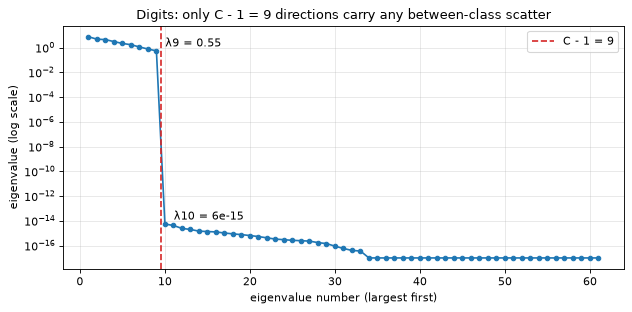

In [8]:
X_digits, y_digits = load_digits(return_X_y=True)
varying = X_digits.std(axis=0) > 0                       # 3 border pixels are always 0 -> drop them
Xd = X_digits[:, varying]
Sw_d, Sb_d = scatter_matrices(Xd, y_digits)
eigenvalues_d = eigh(Sb_d, Sw_d, eigvals_only=True)[::-1]

print(f"digits: {len(np.unique(y_digits))} classes, {Xd.shape[1]} varying pixels")
print("rank of Sb:", np.linalg.matrix_rank(Sb_d), "  (C - 1 =", len(np.unique(y_digits)) - 1, ")")
print("top 12 generalised eigenvalues:", eigenvalues_d[:12])

X_wine, y_wine = load_wine(return_X_y=True)
try:
    LinearDiscriminantAnalysis(n_components=3).fit(X_wine, y_wine)   # wine: 3 classes, 13 features
except ValueError as error:
    print("\nwine, n_components=3 ->", error)

fig, ax = plt.subplots(figsize=(8, 4))
ranks = np.arange(1, len(eigenvalues_d) + 1)
ax.semilogy(ranks, np.maximum(eigenvalues_d, 1e-17), "o-", ms=4)    # round-off can give tiny negatives: floor at 1e-17
ax.axvline(9.5, color="tab:red", ls="--", label="C - 1 = 9")
ax.annotate(f"λ9 = {eigenvalues_d[8]:.2f}", (9, eigenvalues_d[8]), textcoords="offset points", xytext=(8, 4))
ax.annotate(f"λ10 = {eigenvalues_d[9]:.0e}", (10, max(eigenvalues_d[9], 1e-17)), textcoords="offset points",
            xytext=(8, 4))
ax.set_xlabel("eigenvalue number (largest first)"); ax.set_ylabel("eigenvalue (log scale)")
ax.set_title("Digits: only C - 1 = 9 directions carry any between-class scatter"); ax.legend()
plt.tight_layout(); plt.show()

> **How to read this**
> * The rank of $S_B$ is **9** = $C - 1$, even though there are 61 pixels.
> * The first nine eigenvalues run from 7.585 down to 0.546; the tenth is $6 \times 10^{-15}$, i.e. zero up to
>   round-off. On the log plot that is a cliff of about 14 orders of magnitude right after the red line.
> * scikit-learn enforces the same limit: asking for 3 components on wine (3 classes) raises
>   “n_components cannot be larger than min(n_features, n_classes - 1)”.
> * Practical consequence: binary classification gives **exactly one** LDA axis. If you want more output features than
>   $C - 1$, LDA is the wrong tool (PCA, PLS or feature selection are not limited this way).

## Lab 5 · The same answer from a different question: LDA as a Gaussian classifier

**Goal:** LDA has a second, completely different derivation. Assume each class is a **Gaussian** (bell-shaped) cloud,
all classes share **one covariance matrix** $\Sigma$, and class $k$ has prior probability $\pi_k$ (its share of the
data). Bayes' rule then gives a classifier. Claim:

1. its boundary is a **straight line** (a flat plane in more dimensions),
2. its direction is **the same** as Fisher's direction from Lab 2,
3. scikit-learn's `predict_proba` is exactly this formula.

We reuse the Lab 2 data. (The `lsqr` solver is used because it stores `covariance_` with the same divide-by-$n$
formula as the hand computation.)

<details>
<summary><b>Proof: shared-covariance Gaussians give a linear boundary along Fisher's direction (click to expand)</b></summary>

**Symbols.** $p$ = number of features. $\mu_k$ = mean of class $k$; $\Sigma$ = the shared $p \times p$ covariance;
$\Sigma^{-1}$ its inverse; $|\Sigma|$ its determinant (a single number). $\pi_k$ = prior probability of class $k$.
The Gaussian density is

$$f_k(x) = \frac{1}{(2\pi)^{p/2} |\Sigma|^{1/2}} \exp\!\Big(-\tfrac12 (x - \mu_k)^\top \Sigma^{-1} (x - \mu_k)\Big)$$

$\exp(t) = e^t$ and $\log$ is its inverse (natural logarithm).

**Step 1: Bayes' rule.** $P(k \mid x) = \dfrac{\pi_k f_k(x)}{\sum_j \pi_j f_j(x)}$. The bottom is the same for every
class, so the predicted class is the one with the largest $\log(\pi_k f_k(x))$.

**Step 2: expand.** Dropping terms that are the same for every class ($(2\pi)^{p/2}$ and $|\Sigma|$, because $\Sigma$
is shared):

$$\log(\pi_k f_k(x)) = -\tfrac12 x^\top \Sigma^{-1} x + x^\top \Sigma^{-1}\mu_k - \tfrac12 \mu_k^\top \Sigma^{-1}\mu_k + \log \pi_k + \text{const}$$

The first term $-\tfrac12 x^\top \Sigma^{-1} x$ is the **same for every class** (because $\Sigma$ is shared) and
cancels when classes are compared. What remains is the **discriminant score**

$$\delta_k(x) = x^\top \Sigma^{-1}\mu_k - \tfrac12 \mu_k^\top \Sigma^{-1}\mu_k + \log \pi_k$$

which is **linear** in $x$ (no $x$ multiplied by $x$). `predict_proba` is
$P(k \mid x) = e^{\delta_k(x)} / \sum_j e^{\delta_j(x)}$, which is what the code computes by hand.

**Step 3: the boundary.** Between classes 0 and 1 the boundary is $\delta_1(x) = \delta_0(x)$:

$$x^\top \Sigma^{-1}(\mu_1 - \mu_0) = \tfrac12\big(\mu_1^\top \Sigma^{-1}\mu_1 - \mu_0^\top \Sigma^{-1}\mu_0\big) - \log\frac{\pi_1}{\pi_0}$$

The left side is a projection onto $w = \Sigma^{-1}(\mu_1 - \mu_0)$; the right side is a fixed number. So the boundary
is a straight line at right angles to $w$, and the class probability depends on $x$ **only through its projection**
$w^\top x$.

**Step 4: same direction as Fisher.** The usual estimate of the shared covariance is the pooled within-class scatter
divided by $n$: $\hat\Sigma = S_W / n$. So $w = \hat\Sigma^{-1}(\mu_1 - \mu_0) = n\, S_W^{-1}(m_1 - m_0)$ — Fisher's
direction (Lab 2, Step 4) times a constant. Two different questions, one answer.

**If the classes do NOT share a covariance** ($\Sigma_k$ per class), the $-\tfrac12 x^\top \Sigma_k^{-1} x$ terms are
different and do not cancel: the boundary becomes curved (quadratic). That is **QDA** (Lab 13). The priors
$\pi_k$ only move the threshold, not the direction (Lab 16).

</details>

In [9]:
lda_bf = LinearDiscriminantAnalysis(solver="lsqr").fit(X_bf, y_bf)   # same data as Lab 2

priors = np.array([np.mean(y_bf == k) for k in (0, 1)])
means = np.array([X_bf[y_bf == k].mean(axis=0) for k in (0, 1)])
Sigma = Sw_bf / len(X_bf)                       # one shared covariance = within-class scatter / n
Sigma_inv = np.linalg.inv(Sigma)

# Gaussian score for each class, delta_k(x) = x' Σ^-1 μ_k - ½ μ_k' Σ^-1 μ_k + log π_k   (linear in x)
delta = np.column_stack([X_bf @ Sigma_inv @ means[k] - 0.5 * means[k] @ Sigma_inv @ means[k] + np.log(priors[k])
                         for k in (0, 1)])
proba_by_hand = np.exp(delta) / np.exp(delta).sum(axis=1, keepdims=True)

print("shared covariance Σ (by hand):\n", Sigma)
print("sklearn covariance_          :\n", lda_bf.covariance_)
print(f"largest |P_by_hand - sklearn predict_proba| = {np.abs(proba_by_hand - lda_bf.predict_proba(X_bf)).max():.1e}")
print(f"|cos| between sklearn coef_ and Fisher's w from Lab 2 = {same_axis(lda_bf.coef_[0], w_bf):.6f}")
print(f"training accuracy = {lda_bf.score(X_bf, y_bf):.3f}")

shared covariance Σ (by hand):
 [[3.022 1.998]
 [1.998 1.964]]
sklearn covariance_          :
 [[3.022 1.998]
 [1.998 1.964]]
largest |P_by_hand - sklearn predict_proba| = 1.1e-15
|cos| between sklearn coef_ and Fisher's w from Lab 2 = 1.000000
training accuracy = 0.833


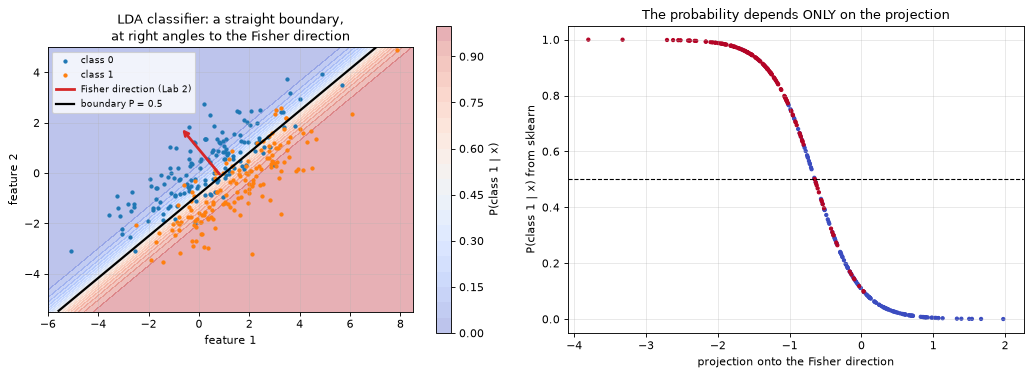

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
ax = axes[0]
g1, g2 = np.meshgrid(np.linspace(-6, 8.5, 300), np.linspace(-5.5, 5, 300))
prob_grid = lda_bf.predict_proba(np.c_[g1.ravel(), g2.ravel()])[:, 1].reshape(g1.shape)
shade = ax.contourf(g1, g2, prob_grid, levels=20, cmap="coolwarm", alpha=0.35)
ax.contour(g1, g2, prob_grid, levels=[0.5], colors="black", linewidths=2)
ax.scatter(*X_bf[y_bf == 0].T, s=8, color="tab:blue", label="class 0")
ax.scatter(*X_bf[y_bf == 1].T, s=8, color="tab:orange", label="class 1")
draw_arrow(ax, X_bf.mean(axis=0), 2.5 * w_bf / np.linalg.norm(w_bf), "tab:red", "Fisher direction (Lab 2)")
ax.plot([], [], color="black", lw=2, label="boundary P = 0.5")
fig.colorbar(shade, ax=ax, label="P(class 1 | x)")
ax.set_aspect("equal"); ax.set_xlabel("feature 1"); ax.set_ylabel("feature 2")
ax.set_xlim(-6, 8.5); ax.set_ylim(-5.5, 5)
ax.set_title("LDA classifier: a straight boundary,\nat right angles to the Fisher direction")
ax.legend(fontsize=8, loc="upper left")

ax = axes[1]
z_bf = X_bf @ (w_bf / np.linalg.norm(w_bf))
ax.scatter(z_bf, lda_bf.predict_proba(X_bf)[:, 1], c=y_bf, cmap="coolwarm", s=8)
ax.axhline(0.5, color="black", lw=1, ls="--")
ax.set_xlabel("projection onto the Fisher direction"); ax.set_ylabel("P(class 1 | x) from sklearn")
ax.set_title("The probability depends ONLY on the projection")
plt.tight_layout(); plt.show()

> **How to read this**
> * The shared covariance computed by hand, $S_W / n$, equals scikit-learn's `covariance_`
>   (`[[3.022, 1.998], [1.998, 1.964]]`).
> * The hand-computed probabilities match `predict_proba` to $1.1 \times 10^{-15}$ (round-off): scikit-learn's LDA
>   classifier **is** the shared-covariance Gaussian formula.
> * $|\cos| = 1.000000$ between scikit-learn's `coef_` and Fisher's direction from Lab 2: the Gaussian view and the
>   “best projection” view find the same axis.
> * **Left:** the black boundary is a straight line at right angles to the red Fisher arrow. The shading changes only
>   as you move along the arrow.
> * **Right:** plotted against the projection onto the Fisher direction, the probabilities of all 300 points fall on
>   a single S-shaped curve. Two points with the same projection get the same probability, wherever they are.
> * Training accuracy is 0.833: the classes overlap (look at the left plot), so no straight line can do much better.

---
# Part B — Why LDA is useful in ML

## Lab 6 · LDA vs PCA on the same data

**Goal:** both PCA and LDA find a “best” direction to project onto, but they answer different questions.
PCA (unsupervised) keeps the direction with the most **variance**; LDA (supervised) keeps the direction with the most
**class separation**. Here the two classes differ only along the *short* axis of a long, thin cloud.
For each 1-D projection we print the share of the variance kept, Fisher's $J$, and the 5-fold accuracy of a logistic
regression trained on that single number. Then the same comparison on the wine data (13 features → 2).

In [11]:
rng = np.random.default_rng(1)
spin = np.radians(20)
rotation = np.array([[np.cos(spin), -np.sin(spin)], [np.sin(spin), np.cos(spin)]])
cigar = rotation @ np.diag([9.0, 0.4]) @ rotation.T          # long axis at 20°, short axis at 110°
gap = rotation @ np.array([0.0, 1.6])                         # classes differ along the SHORT axis  <- try changing
X_cig = np.vstack([rng.multivariate_normal(-gap / 2, cigar, 300), rng.multivariate_normal(gap / 2, cigar, 300)])
y_cig = np.repeat([0, 1], 300)

pc1 = PCA(n_components=1).fit(X_cig).components_[0]
ld1 = LinearDiscriminantAnalysis(solver="eigen").fit(X_cig, y_cig).scalings_[:, 0]
ld1 = ld1 / np.linalg.norm(ld1)
total_variance = X_cig.var(axis=0).sum()
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
for name, u, reducer in [("PCA  (PC1)", pc1, PCA(n_components=1)),
                         ("LDA  (LD1)", ld1, LinearDiscriminantAnalysis(n_components=1))]:
    acc = cross_val_score(make_pipeline(reducer, LogisticRegression()), X_cig, y_cig, cv=cv).mean()
    print(f"{name}: θ = {angle_of(u):5.1f}°, variance kept = {(X_cig @ u).var() / total_variance:5.1%},"
          f"  Fisher ratio J = {fisher_ratio(X_cig, y_cig, u):.3f},  1-D accuracy = {acc:.3f}")

PCA  (PC1): θ =  20.4°, variance kept = 89.7%,  Fisher ratio J = 0.000,  1-D accuracy = 0.490
LDA  (LD1): θ = 110.9°, variance kept = 10.3%,  Fisher ratio J = 1.502,  1-D accuracy = 0.885


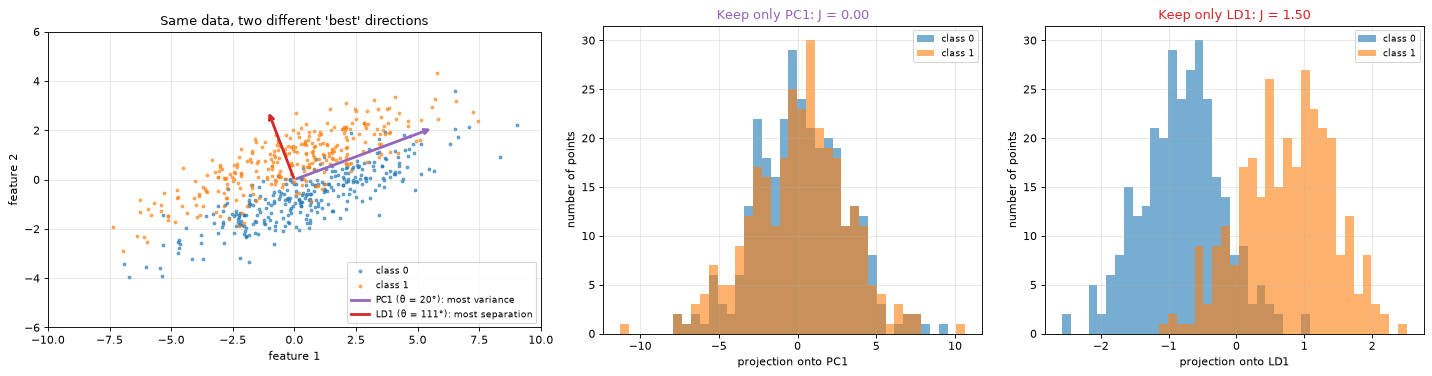

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), gridspec_kw={"width_ratios": [1.3, 1, 1]})
ax = axes[0]
ax.scatter(*X_cig[y_cig == 0].T, s=6, alpha=0.6, color="tab:blue", label="class 0")
ax.scatter(*X_cig[y_cig == 1].T, s=6, alpha=0.6, color="tab:orange", label="class 1")
draw_arrow(ax, (0, 0), 6 * pc1, "tab:purple", f"PC1 (θ = {angle_of(pc1):.0f}°): most variance")
draw_arrow(ax, (0, 0), 3 * ld1 * np.sign(ld1[1]), "tab:red", f"LD1 (θ = {angle_of(ld1):.0f}°): most separation")
ax.set_aspect("equal"); ax.set_xlim(-10, 10); ax.set_ylim(-6, 6)
ax.set_xlabel("feature 1"); ax.set_ylabel("feature 2"); ax.legend(fontsize=8, loc="lower right")
ax.set_title("Same data, two different 'best' directions")
for ax, u, name, color in [(axes[1], pc1, "PC1", "tab:purple"), (axes[2], ld1, "LD1", "tab:red")]:
    z = X_cig @ u
    bins = np.linspace(z.min(), z.max(), 40)
    ax.hist(z[y_cig == 0], bins=bins, alpha=0.6, color="tab:blue", label="class 0")
    ax.hist(z[y_cig == 1], bins=bins, alpha=0.6, color="tab:orange", label="class 1")
    ax.set_xlabel(f"projection onto {name}"); ax.set_ylabel("number of points"); ax.legend(fontsize=8)
    ax.set_title(f"Keep only {name}: J = {fisher_ratio(X_cig, y_cig, u):.2f}", color=color)
plt.tight_layout(); plt.show()

PCA: J(axis 1) + J(axis 2) =  6.599,  5-fold accuracy of logistic regression on 2 axes = 0.961


LDA: J(axis 1) + J(axis 2) = 13.210,  5-fold accuracy of logistic regression on 2 axes = 0.989


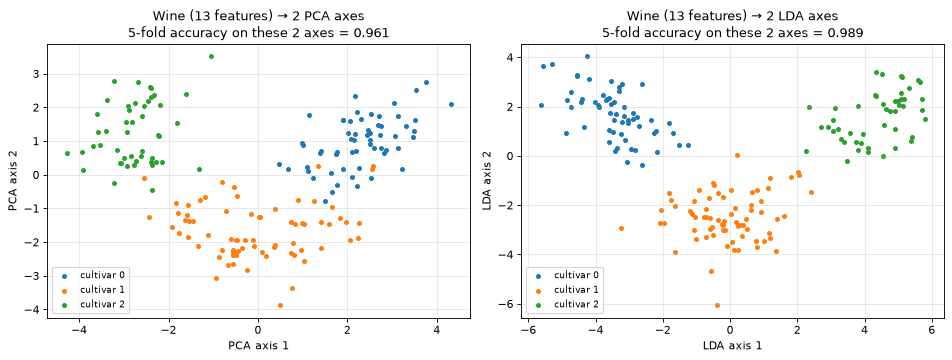

In [13]:
wine_pca = make_pipeline(StandardScaler(), PCA(n_components=2))
wine_lda = make_pipeline(StandardScaler(), LinearDiscriminantAnalysis(n_components=2))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, reducer, name in [(axes[0], wine_pca, "PCA"), (axes[1], wine_lda, "LDA")]:
    Z = reducer.fit_transform(X_wine, y_wine)
    for k, c in zip(range(3), ["tab:blue", "tab:orange", "tab:green"]):
        ax.scatter(*Z[y_wine == k].T, s=12, color=c, label=f"cultivar {k}")
    acc = cross_val_score(make_pipeline(*[step for _, step in reducer.steps], LogisticRegression()),
                          X_wine, y_wine, cv=cv).mean()
    J = sum(fisher_ratio(Z, y_wine, e) for e in np.eye(2))
    ax.set_xlabel(f"{name} axis 1"); ax.set_ylabel(f"{name} axis 2"); ax.legend(fontsize=8)
    ax.set_title(f"Wine (13 features) → 2 {name} axes\n5-fold accuracy on these 2 axes = {acc:.3f}")
    print(f"{name}: J(axis 1) + J(axis 2) = {J:6.3f},  5-fold accuracy of logistic regression on 2 axes = {acc:.3f}")
plt.tight_layout(); plt.show()

> **How to read this**
> * **Two different winners.** PC1 points along the cloud (20.4°) and keeps 89.7 % of the variance — but its Fisher
>   ratio is 0.000 and a classifier on it scores 0.490 (coin flip). LD1 points across the cloud (110.9°), keeps only
>   10.3 % of the variance, yet has $J = 1.502$ and 0.885 accuracy.
> * **Histograms:** on PC1 the two classes are on top of each other; on LD1 they form two separate humps.
> * PCA is not “wrong” — it answers *where is the data spread out?* If the label lives in a low-variance direction
>   (the PCA lab's Lab 12 shows the same thing), PCA throws it away and LDA keeps it.
> * **Wine:** both 2-D maps show three groups, but the LDA map spreads them further apart (sum of the two axes'
>   Fisher ratios 13.210 vs 6.599), and logistic regression on the 2 LDA axes scores 0.989 vs 0.961 on the 2 PCA axes.
> * Both are inside a `Pipeline` with the classifier, so each fold fits PCA/LDA on its training rows only (Lab 12
>   shows why that matters much more for LDA).

## Lab 7 · Ten classes in two dimensions (digits)

**Goal:** squeeze the 64-pixel digit images into **2** numbers per image with PCA and with LDA, and compare the maps.
Each digit's label sits at the median of its points (a thin line connects it if it had to be nudged to avoid
overlapping another label). The maps are fitted on all images, just for the picture; the accuracy in each title is
5-fold cross-validated with the reducer inside a `Pipeline`.

PCA: 5-fold accuracy of 5-nearest-neighbours on 2 axes = 0.620
LDA: 5-fold accuracy of 5-nearest-neighbours on 2 axes = 0.652


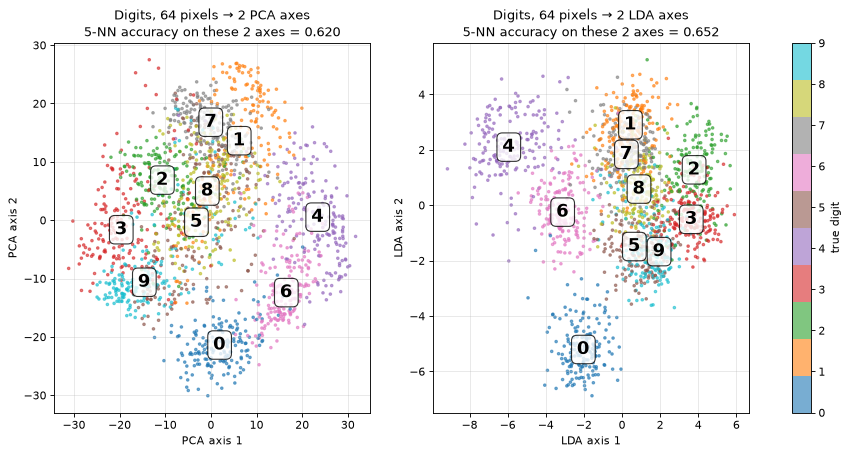

In [14]:
def spread_labels(points, min_gap):
    """Nudge label positions apart until no two are closer than `min_gap` (so the labels don't overlap)."""
    points = points.astype(float).copy()
    for _ in range(200):
        for i in range(len(points)):
            for j in range(i + 1, len(points)):
                gap = points[j] - points[i]
                distance = max(np.linalg.norm(gap), 1e-9)
                if distance < min_gap:
                    push = (min_gap - distance) / 2 * gap / distance
                    points[i] -= push
                    points[j] += push
    return points


fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, reducer, name in [(axes[0], PCA(n_components=2), "PCA"),
                          (axes[1], LinearDiscriminantAnalysis(n_components=2), "LDA")]:
    Z = reducer.fit_transform(X_digits, y_digits)
    points = ax.scatter(Z[:, 0], Z[:, 1], c=y_digits, cmap="tab10", s=5, alpha=0.6)
    spread = Z.std(axis=0)                                  # work in "standard deviations" so both axes count equally
    centres = np.array([np.median(Z[y_digits == digit], axis=0) for digit in range(10)])
    labels = spread_labels(centres / spread, min_gap=0.45) * spread
    for digit in range(10):
        ax.plot(*np.c_[centres[digit], labels[digit]], color="black", lw=0.8)   # line back to the true centre
        ax.text(*labels[digit], str(digit), fontsize=16, weight="bold",
                ha="center", va="center", bbox=dict(boxstyle="round", fc="white", alpha=0.8))
    acc = cross_val_score(make_pipeline(type(reducer)(n_components=2), KNeighborsClassifier()),
                          X_digits, y_digits, cv=cv).mean()
    ax.set_xlabel(f"{name} axis 1"); ax.set_ylabel(f"{name} axis 2")
    ax.set_title(f"Digits, 64 pixels → 2 {name} axes\n5-NN accuracy on these 2 axes = {acc:.3f}")
    print(f"{name}: 5-fold accuracy of 5-nearest-neighbours on 2 axes = {acc:.3f}")
fig.colorbar(points, ax=axes, label="true digit", ticks=range(10))
plt.show()

> **How to read this**
> * **PCA map:** 0, 4, 6, 3 and 9 form their own islands at the edges, but 1, 2, 5, 7 and 8 pile up in the middle.
>   PCA spread the images along the directions in which *pixels* vary most, whatever the digit.
> * **LDA map:** the axes are chosen to push the 10 class centres apart relative to the spread within each class.
>   0, 4 and 6 are pushed far out; 2 and 3 separate from the middle group.
> * Still, 2 axes cannot hold 10 classes: a 5-nearest-neighbour classifier on the 2 LDA axes scores 0.652 vs 0.620 on
>   the 2 PCA axes. Better, but far from good — LDA has up to 9 axes to use (Lab 8).

## Lab 8 · LDA as a preprocessing step: how many axes?

**Goal:** use LDA (or PCA) to reduce the digits, then classify with 5-nearest-neighbours, for every number of kept
components $k$. LDA stops at $k = 9$ (Lab 4); PCA can go on. The dashed line is 5-NN on all 64 raw pixels.

k              :     1     2     3     4     5     6     7     8     9
LDA → 5-NN     : 0.401 0.652 0.835 0.899 0.929 0.943 0.952 0.963 0.966
PCA → 5-NN     : 0.341 0.620 0.762 0.859 0.920 0.937 0.954 0.963 0.976
PCA, k = 12-40 : 0.978 0.983 0.983 0.984 0.986
5-NN on all 64 pixels = 0.986


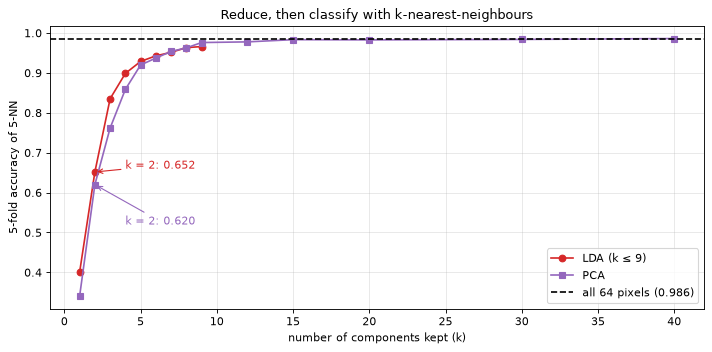

In [15]:
ks = range(1, 10)                                           # LDA can give at most C - 1 = 9 axes
acc_lda = [cross_val_score(make_pipeline(LinearDiscriminantAnalysis(n_components=k), KNeighborsClassifier()),
                           X_digits, y_digits, cv=cv).mean() for k in ks]
ks_pca = [1, 2, 3, 4, 5, 6, 7, 8, 9, 12, 15, 20, 30, 40]
acc_pca = [cross_val_score(make_pipeline(PCA(n_components=k), KNeighborsClassifier()),
                           X_digits, y_digits, cv=cv).mean() for k in ks_pca]
acc_all = cross_val_score(KNeighborsClassifier(), X_digits, y_digits, cv=cv).mean()

print("k              :", " ".join(f"{k:5d}" for k in ks))
print("LDA → 5-NN     :", " ".join(f"{a:.3f}" for a in acc_lda))
print("PCA → 5-NN     :", " ".join(f"{a:.3f}" for a in acc_pca[:9]))
print("PCA, k = 12-40 :", " ".join(f"{a:.3f}" for a in acc_pca[9:]))
print(f"5-NN on all 64 pixels = {acc_all:.3f}")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(list(ks), acc_lda, "o-", color="tab:red", label="LDA (k ≤ 9)")
ax.plot(ks_pca, acc_pca, "s-", color="tab:purple", label="PCA")
ax.axhline(acc_all, color="black", ls="--", label=f"all 64 pixels ({acc_all:.3f})")
for acc, color, text_y in [(acc_lda[1], "tab:red", 0.66), (acc_pca[1], "tab:purple", 0.52)]:
    ax.annotate(f"k = 2: {acc:.3f}", (2, acc), xytext=(4, text_y), color=color,
                arrowprops=dict(arrowstyle="->", color=color))
ax.set_xlabel("number of components kept (k)"); ax.set_ylabel("5-fold accuracy of 5-NN")
ax.set_title("Reduce, then classify with k-nearest-neighbours"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

> **How to read this**
> * **With very few axes, LDA wins clearly:** at $k = 3$ it scores 0.835 vs PCA's 0.762, at $k = 4$ 0.899 vs 0.859.
>   When you can only afford a handful of features, choosing them by class separation pays off.
> * **From $k = 5$ on, the two are close** (0.929 vs 0.920 at $k = 5$; both 0.963 at $k = 8$), and at $k = 9$ PCA
>   is slightly ahead (0.976 vs 0.966).
> * PCA can keep going: 0.983 at 15 components and 0.986 at 40, equal to all 64 pixels (0.986). LDA is capped at 9.
> * Lesson: LDA is an excellent **compressor down to C − 1 dimensions**. It is not automatically the best feature
>   extractor for a flexible model such as k-NN, which can use extra dimensions that LDA is not allowed to give it.

## Lab 9 · LDA as a classifier vs QDA vs logistic regression

**Goal:** compare three classifiers that all produce class probabilities.

* **LDA:** Gaussians with **one shared** covariance → straight boundaries.
* **QDA:** Gaussians with **one covariance per class** → curved boundaries, many more numbers to estimate.
  (`reg_param=0.01` adds a tiny bit of shrinkage; without it QDA crashes on digits because some pixels never vary
  inside a class.)
* **Logistic regression:** also straight boundaries, but it models $P(\text{class} \mid x)$ directly and assumes
  nothing about how $x$ is distributed.

First on four real datasets (5-fold accuracy), then on data that follows LDA's assumption **exactly**, as the number
of training rows grows.

In [16]:
X_cancer, y_cancer = load_breast_cancer(return_X_y=True)
models = {
    "LDA": LinearDiscriminantAnalysis(),
    "QDA": QuadraticDiscriminantAnalysis(reg_param=0.01),    # small regularisation, else digits crashes
    "logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
}
print(f"{'dataset':15s}" + "".join(f"{name:>22s}" for name in models))
for data_name, X, y in [("iris", X_iris, y_iris), ("wine", X_wine, y_wine),
                        ("breast_cancer", X_cancer, y_cancer), ("digits", X_digits, y_digits)]:
    scores = [cross_val_score(model, X, y, cv=cv).mean() for model in models.values()]
    print(f"{data_name:15s}" + "".join(f"{s:22.3f}" for s in scores))

dataset                           LDA                   QDA   logistic regression
iris                            0.980                 0.973                 0.960
wine                            0.994                 0.994                 0.983
breast_cancer                   0.954                 0.949                 0.979


digits                          0.951                 0.963                 0.969


 rows per class                   LDA                   QDA   logistic regression
             12                 0.705                 0.585                 0.732
             20                 0.764                 0.668                 0.769
             40                 0.794                 0.731                 0.795
             80                 0.808                 0.773                 0.807
            160                 0.815                 0.796                 0.815
            320                 0.819                 0.810                 0.819
best achievable (LDA trained on 100 000 rows): 0.823


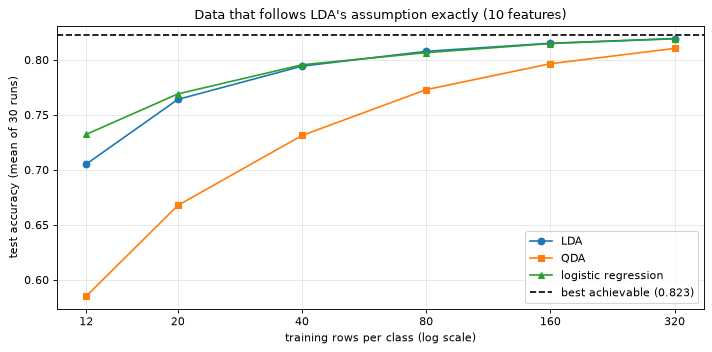

In [17]:
rng = np.random.default_rng(0)
p = 10                                                       # number of features   <- try changing this
A = rng.normal(size=(p, p))
cov_true = A @ A.T / p + np.eye(p)                           # one shared, correlated covariance
mu_true = rng.normal(size=p) * 0.35

def sample(n_per_class):
    """Two Gaussian classes with the SAME covariance: exactly LDA's assumption."""
    X = np.vstack([rng.multivariate_normal(-mu_true, cov_true, n_per_class),
                   rng.multivariate_normal(mu_true, cov_true, n_per_class)])
    return X, np.repeat([0, 1], n_per_class)

X_test_lc, y_test_lc = sample(5000)
sizes = [12, 20, 40, 80, 160, 320]                           # training rows PER CLASS
curve = {name: [] for name in models}
for n in sizes:
    runs = {name: [] for name in models}
    for _ in range(30):                                      # average over 30 random training sets
        X_tr, y_tr = sample(n)
        for name, model in models.items():
            runs[name].append(model.fit(X_tr, y_tr).score(X_test_lc, y_test_lc))
    for name in models:
        curve[name].append(np.mean(runs[name]))
best_possible = LinearDiscriminantAnalysis().fit(*sample(50000)).score(X_test_lc, y_test_lc)

print(f"{'rows per class':>15s}" + "".join(f"{name:>22s}" for name in models))
for i, n in enumerate(sizes):
    print(f"{n:15d}" + "".join(f"{curve[name][i]:22.3f}" for name in models))
print(f"best achievable (LDA trained on 100 000 rows): {best_possible:.3f}")

fig, ax = plt.subplots(figsize=(9, 4.5))
for (name, values), marker in zip(curve.items(), ["o", "s", "^"]):
    ax.plot(sizes, values, marker + "-", label=name)
ax.axhline(best_possible, color="black", ls="--", label=f"best achievable ({best_possible:.3f})")
ax.set_xscale("log"); ax.minorticks_off(); ax.set_xticks(sizes); ax.set_xticklabels(sizes)
ax.set_xlabel("training rows per class (log scale)"); ax.set_ylabel("test accuracy (mean of 30 runs)")
ax.set_title(f"Data that follows LDA's assumption exactly ({p} features)"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

> **How to read this**
> * **Real data (first table):** all three are close. LDA is best on iris (0.980) and ties QDA on wine (0.994).
>   Logistic regression is best on breast_cancer (0.979 vs LDA 0.954) and digits (0.969 vs LDA 0.951), where the
>   features are far from Gaussian (for example skewed size measurements in breast_cancer, pixel values 0–16 in digits).
> * **Learning curve (second table, plot):** QDA needs much more data. With 12 rows per class it scores 0.585 against
>   LDA's 0.705, because it must estimate two 10 × 10 covariance matrices (110 numbers) instead of one (55). It is still
>   behind at 320 rows per class (0.810 vs 0.819).
> * LDA and logistic regression are tied from 40 rows per class on (0.794 / 0.795), and both approach the best
>   achievable 0.823. At 12 rows logistic regression is slightly ahead (0.732 vs 0.705): scikit-learn's logistic
>   regression has built-in regularisation (`C=1.0`), which helps a lot with so few rows. Plain LDA has none —
>   Lab 10 adds it.
> * Rule of thumb: when classes really are similar-shaped blobs, LDA is as good as anything and needs no tuning.
>   QDA pays for its flexibility with data. Logistic regression is the safer choice when the features are clearly
>   not Gaussian.

## Lab 10 · Shrinkage: LDA when there are more features than rows

**Goal:** LDA needs the inverse of $S_W$. With $n$ rows and $C$ classes, $S_W$ can have at most $n - C$ independent
directions, so once the number of features $p$ exceeds $n - C$ it has **no inverse** and plain LDA becomes
unreliable. **Shrinkage** fixes this by blending the estimated covariance with a simple, always-invertible one.

Setup: only 20 training rows (10 per class). Feature 0 carries the label; every other feature is pure noise. We add
more and more noise features and compare plain LDA, Ledoit–Wolf shrinkage (`shrinkage="auto"`) and the OAS estimator,
averaged over 50 random training sets and tested on 1 000 fresh rows.

<details>
<summary><b>Explanation: why $S_W$ has no inverse when $p > n - C$, and what shrinkage does (click to expand)</b></summary>

**Why $S_W$ breaks.** Class $k$ contributes the vectors $x_i - m_k$ for its $n_k$ points. These always add up to
zero ($\sum_{i \in k}(x_i - m_k) = n_k m_k - n_k m_k = 0$), so only $n_k - 1$ of them are independent. Adding over
all classes, $S_W$ is built from at most $\sum_k (n_k - 1) = n - C$ independent directions:

$$\text{rank}(S_W) \le n - C$$

With $p > n - C$ features there is a direction $w$ with $w^\top S_W w = 0$: along it, **every training point sits
exactly on its own class mean**. Then $J(w) = w^\top S_B w / 0$ is infinite. LDA happily picks that direction, but it
is an accident of these particular 20 rows (pure noise), so it fails on new data. Just below the limit, $S_W$ is
barely invertible, its inverse blows up tiny noisy directions, and accuracy is at its worst.

**What shrinkage does.** Let $\hat\Sigma$ be the estimated within-class covariance, $\text{tr}(\hat\Sigma)$ its
**trace** (the sum of its diagonal entries = the total variance over all features), and $\bar\nu = \text{tr}(\hat\Sigma)/p$
the average variance of one feature. Shrinkage replaces $\hat\Sigma$ by

$$\hat\Sigma_{\text{shrunk}} = (1 - \alpha)\, \hat\Sigma + \alpha\, \bar\nu\, I, \qquad 0 \le \alpha \le 1$$

a blend of “what the data says” and “every feature has the same variance and no correlation”. The second part has
all eigenvalues equal to $\bar\nu > 0$, so for any $\alpha > 0$ the blend always has an inverse. It also pulls the
too-small eigenvalues up and the too-large ones down, which is exactly the error a small sample makes.

**Choosing $\alpha$.** `shrinkage="auto"` uses the **Ledoit–Wolf** formula, which estimates from the data the $\alpha$
that minimises the expected squared error of $\hat\Sigma_{\text{shrunk}}$ (scikit-learn standardises the features
first, then undoes it). **OAS** (Oracle Approximating Shrinkage) is a variant with a better $\alpha$ when the data is
roughly Gaussian. A fixed number such as `shrinkage=0.3` also works, but then you must tune it (Lab 11 shows a
catch). Shrinkage needs `solver="lsqr"` or `solver="eigen"`; the default `svd` solver does not support it.

</details>

n = 20 rows, p = 50 features: rank of Sw = 18 (needs 50 to be invertible)
features p                    no shrinkage  shrinkage='auto' (Ledoit-Wolf)                   OAS estimator
         1                           0.975                           0.975                           0.975
         5                           0.953                           0.968                           0.970
        10                           0.895                           0.961                           0.965
        15                           0.823                           0.957                           0.962
        20                           0.743                           0.953                           0.959
        30                           0.791                           0.942                           0.954
        50                           0.766                           0.923                           0.937
        75                           0.715                           0

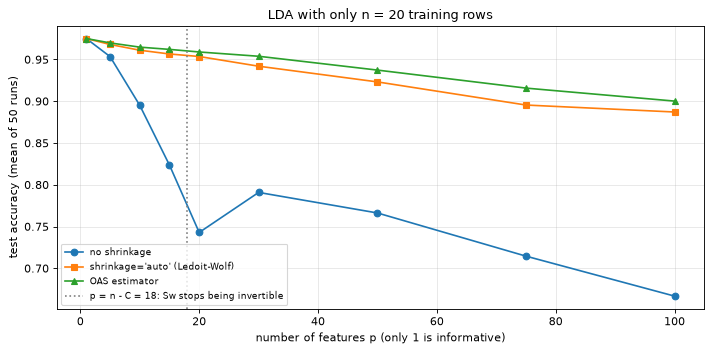

In [18]:
rng = np.random.default_rng(0)
n_train = 20                                                 # 10 rows per class  <- try changing this
feature_counts = [1, 5, 10, 15, 20, 30, 50, 75, 100]

def make_data(n, p):
    """Feature 0 carries the label (class means -2 and +2); the other p - 1 features are pure noise."""
    y = np.repeat([0, 1], n // 2)
    X = rng.normal(size=(n, p))
    X[:, 0] += np.where(y == 1, 2.0, -2.0)
    return X, y

variants = {
    "no shrinkage": dict(solver="lsqr"),
    "shrinkage='auto' (Ledoit-Wolf)": dict(solver="lsqr", shrinkage="auto"),
    "OAS estimator": dict(solver="lsqr", covariance_estimator=OAS()),
}
results = {name: [] for name in variants}
for p in feature_counts:
    runs = {name: [] for name in variants}
    for _ in range(50):
        X_tr, y_tr = make_data(n_train, p)
        X_te, y_te = make_data(1000, p)
        for name, kwargs in variants.items():
            runs[name].append(LinearDiscriminantAnalysis(**kwargs).fit(X_tr, y_tr).score(X_te, y_te))
    for name in variants:
        results[name].append(np.mean(runs[name]))

X_tr, y_tr = make_data(n_train, 50)
print(f"n = {n_train} rows, p = 50 features: rank of Sw = {np.linalg.matrix_rank(scatter_matrices(X_tr, y_tr)[0])}"
      " (needs 50 to be invertible)")
print(f"{'features p':>10s}" + "".join(f"{name:>32s}" for name in variants))
for i, p in enumerate(feature_counts):
    print(f"{p:10d}" + "".join(f"{results[name][i]:32.3f}" for name in variants))

fig, ax = plt.subplots(figsize=(9, 4.5))
for (name, values), marker in zip(results.items(), ["o", "s", "^"]):
    ax.plot(feature_counts, values, marker + "-", label=name)
ax.axvline(n_train - 2, color="gray", ls=":", label=f"p = n - C = {n_train - 2}: Sw stops being invertible")
ax.set_xlabel("number of features p (only 1 is informative)"); ax.set_ylabel("test accuracy (mean of 50 runs)")
ax.set_title(f"LDA with only n = {n_train} training rows"); ax.legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()

> **How to read this**
> * With 20 rows and 50 features, $S_W$ has rank 18 ($= n - C = 20 - 2$), far short of the 50 needed for an inverse.
> * **Plain LDA (blue)** is excellent with 1 feature (0.975) but collapses as noise features are added: 0.895 at 10
>   features, **0.743 at 20** (just past the $p = n - C = 18$ line, where $S_W$ is barely or not invertible), and 0.667
>   at 100. The small bounce at 30 (0.791) is real: right at the limit the inverse is at its most unstable, and past
>   it `lsqr` falls back to the smallest possible solution.
> * **Shrinkage (orange, green)** degrades gracefully: at 100 features (5× more features than rows) Ledoit–Wolf still
>   scores 0.887 and OAS 0.900.
> * Shrinkage costs almost nothing when it is not needed (all three are 0.975 with 1 feature). With few rows per
>   class, `LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto")` is the sensible default.

## Lab 11 · Scaling: plain LDA doesn't care about units

**Goal:** PCA changes completely when a feature's units change (see the PCA lab's Lab 10). Does LDA? On wine we
compare three versions of each model: raw features, proline multiplied by 1 000 (a change of units), and standardised
features (`StandardScaler`). The last column says what fraction of the 178 wines get the same predicted class with and
without standardising.

<details>
<summary><b>Proof: rescaling the features changes nothing in plain LDA (click to expand)</b></summary>

**Setup.** Any change of units, or standardising, maps each point $x$ to $x' = A x + b$, where $A$ is an invertible
$p \times p$ matrix (for a change of units it is diagonal: each feature multiplied by its own factor) and $b$ a shift.

**Step 1.** Shifts cancel in every “point minus mean”, and $x'_i - m'_k = A(x_i - m_k)$. So

$$S_W' = A\, S_W\, A^\top, \qquad S_B' = A\, S_B\, A^\top$$

**Step 2.** For any direction $w$ in the old units take $w' = A^{-\top} w$ (the inverse of $A^\top$ applied to $w$).
Then $w'^\top S_W' w' = w^\top A^{-1} A S_W A^\top A^{-\top} w = w^\top S_W w$, and the same for $S_B$. So
$J'(w') = J(w)$: every direction in the old units has a partner in the new units with exactly the same Fisher ratio.
The best direction in the new units is the partner of the best direction in the old units.

**Step 3.** The projections are identical too: $w'^\top x' = w^\top A^{-1}(A x + b) = w^\top x + \text{const}$.
Same projections → same classification. (The same holds for the Gaussian view: the log-densities differ only by a
constant.)

**Why fixed shrinkage breaks this.** The shrinkage target $\bar\nu I$ (Lab 10) treats every feature as having the
same variance. That is only fair if the features are on comparable scales. In raw wine units, proline's variance
(about $10^5$) dwarfs all the others (magnesium is next at about 200; 11 of the 13 are below 12), so
$\bar\nu$ (about 1 000 to 3 700 inside the three classes) is huge compared with the variance of every feature except
proline, and the blend washes out their real covariance. `shrinkage="auto"` avoids this because scikit-learn
standardises internally before computing the Ledoit–Wolf estimate.

</details>

In [19]:
X_wine_mg = X_wine.copy()
X_wine_mg[:, 12] *= 1000                                     # proline in different units: ×1000  <- try changing
setups = {
    "plain LDA": lambda: LinearDiscriminantAnalysis(),
    "LDA, shrinkage='auto'": lambda: LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto"),
    "LDA, shrinkage=0.5 (fixed)": lambda: LinearDiscriminantAnalysis(solver="lsqr", shrinkage=0.5),
}
print(f"{'model':28s} {'raw':>7s} {'proline×1000':>13s} {'standardised':>13s} {'same predictions?':>18s}")
for name, make in setups.items():
    raw = cross_val_score(make(), X_wine, y_wine, cv=cv).mean()
    units = cross_val_score(make(), X_wine_mg, y_wine, cv=cv).mean()
    scaled = cross_val_score(make_pipeline(StandardScaler(), make()), X_wine, y_wine, cv=cv).mean()
    agree = np.mean(make().fit(X_wine, y_wine).predict(X_wine) ==
                    make_pipeline(StandardScaler(), make()).fit(X_wine, y_wine).predict(X_wine))
    print(f"{name:28s} {raw:7.3f} {units:13.3f} {scaled:13.3f} {agree:17.1%}")

model                            raw  proline×1000  standardised  same predictions?
plain LDA                      0.994         0.994         0.994            100.0%
LDA, shrinkage='auto'          0.983         0.983         0.983            100.0%
LDA, shrinkage=0.5 (fixed)     0.703         0.703         0.989             71.3%


> **How to read this**
> * **Plain LDA:** 0.994 raw, 0.994 with proline in different units, 0.994 standardised, and 100.0 % identical
>   predictions. Unlike PCA, LDA is **unit-free**: it already measures everything relative to the within-class spread.
> * **`shrinkage="auto"`:** also identical in all three columns (0.983) with 100.0 % identical predictions, because
>   scikit-learn standardises internally before choosing the shrinkage.
> * **Fixed `shrinkage=0.5`:** 0.703 on raw features but 0.989 after standardising, and only 71.3 % of the predictions
>   agree. (Multiplying proline by 1 000 changes nothing more, 0.703: proline already dominates the average variance.)
> * Rule: for plain LDA, scaling is optional (harmless, sometimes numerically helpful). **If you use a fixed shrinkage
>   value, standardise first** — or use `shrinkage="auto"`.

---
# Part C — Where LDA fails (and why)

## Lab 12 · Label leakage: fit LDA inside the Pipeline

**Goal:** LDA is **supervised**: it looks at the labels. If you fit it on all the data before cross-validating, the
test folds' labels have already shaped the features. With PCA (unsupervised) this mistake costs a little; with LDA it
can invent a pattern out of nothing. We use 200 rows of **pure random noise** (100 features) with **random labels**,
so the true accuracy of any method is 0.5.

fit LDA on everything, then cross-validate : accuracy 0.845   <- an illusion
LDA inside a Pipeline                      : accuracy 0.510   <- the truth (coin flip)


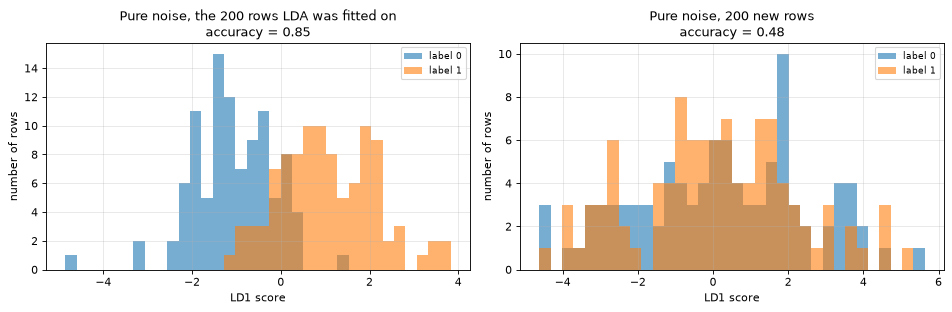

In [20]:
rng = np.random.default_rng(0)
X_noise = rng.normal(size=(200, 100))                        # 200 rows of pure noise, 100 features
y_noise = rng.integers(0, 2, size=200)                       # random labels: the true accuracy is 0.5

# WRONG: fit LDA on all rows (it sees every label), then cross-validate a classifier on its output
Z_leaky = LinearDiscriminantAnalysis(n_components=1).fit_transform(X_noise, y_noise)
leaky = cross_val_score(LogisticRegression(), Z_leaky, y_noise, cv=cv).mean()

# RIGHT: LDA inside the pipeline, so each fold fits it on its own training rows only
honest = cross_val_score(make_pipeline(LinearDiscriminantAnalysis(n_components=1), LogisticRegression()),
                         X_noise, y_noise, cv=cv).mean()
print(f"fit LDA on everything, then cross-validate : accuracy {leaky:.3f}   <- an illusion")
print(f"LDA inside a Pipeline                      : accuracy {honest:.3f}   <- the truth (coin flip)")

lda_noise = LinearDiscriminantAnalysis(n_components=1).fit(X_noise, y_noise)   # the leaky fit, on all 200 rows
X_fresh, y_fresh = rng.normal(size=(200, 100)), rng.integers(0, 2, size=200)    # 200 new rows of the same noise
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, X_part, y_part, title in [(axes[0], X_noise, y_noise, "the 200 rows LDA was fitted on"),
                                  (axes[1], X_fresh, y_fresh, "200 new rows")]:
    z = lda_noise.transform(X_part)[:, 0]
    bins = np.linspace(z.min(), z.max(), 35)
    ax.hist(z[y_part == 0], bins=bins, alpha=0.6, color="tab:blue", label="label 0")
    ax.hist(z[y_part == 1], bins=bins, alpha=0.6, color="tab:orange", label="label 1")
    ax.set_xlabel("LD1 score"); ax.set_ylabel("number of rows"); ax.legend(fontsize=8)
    ax.set_title(f"Pure noise, {title}\naccuracy = {lda_noise.score(X_part, y_part):.2f}")
plt.tight_layout(); plt.show()

> **How to read this**
> * **Wrong way:** fitting LDA on all 200 rows and then cross-validating a classifier on its output reports **0.845**
>   accuracy — on pure noise.
> * **Right way:** with LDA inside the `Pipeline`, each fold fits LDA on its own training rows only, and the score is
>   **0.510**, the coin flip it should be.
> * **Left histogram:** with 100 features LDA can always find *some* direction along which these 200 random labels
>   happen to look separated (accuracy 0.85 on the rows it was fitted on). **Right histogram:** the same direction on
>   200 new noise rows separates nothing (0.48).
> * The more features per row, the worse the illusion (Lab 10: with $p > n - C$ it reaches 100 %). Always put LDA in
>   a `Pipeline` with the model, and fit both on training data only.

## Lab 13 · Classes with different shapes → use QDA

**Goal:** LDA assumes all classes have the **same** covariance (same size, shape and tilt). Here class 0 (blue) is a
tight blob and class 1 (red) is a wide cloud around it. LDA must draw one straight line; QDA estimates a covariance
per class and can draw a curved boundary (Lab 5's proof explains why).

LDA (one shared covariance)     : test accuracy 0.693
QDA (one covariance per class)  : test accuracy 0.887


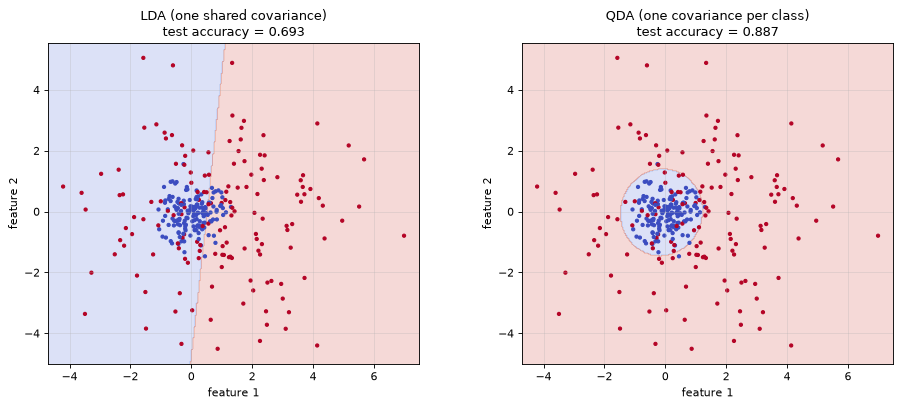

In [21]:
rng = np.random.default_rng(2)
X_uneq = np.vstack([rng.multivariate_normal([0, 0], [[0.3, 0], [0, 0.3]], 300),     # tight class
                    rng.multivariate_normal([1, 0], [[4.0, 0], [0, 4.0]], 300)])    # wide class  <- try 0.3 here
y_uneq = np.repeat([0, 1], 300)
X_tr, X_te, y_tr, y_te = train_test_split(X_uneq, y_uneq, test_size=0.5, random_state=0, stratify=y_uneq)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, model, name in [(axes[0], LinearDiscriminantAnalysis(), "LDA (one shared covariance)"),
                        (axes[1], QuadraticDiscriminantAnalysis(), "QDA (one covariance per class)")]:
    model.fit(X_tr, y_tr)
    plot_regions(ax, model, X_te, y_te, f"{name}\ntest accuracy = {model.score(X_te, y_te):.3f}")
    ax.set_aspect("equal")
    print(f"{name:32s}: test accuracy {model.score(X_te, y_te):.3f}")
plt.tight_layout(); plt.show()

> **How to read this**
> * **LDA** (test accuracy 0.693) can only cut the plane with a straight line, so it gives the whole left half to the
>   tight class and misclassifies every wide-class point on that side.
> * **QDA** (0.887) draws a closed curve around the tight class: “inside the circle → class 0, outside → class 1”.
> * The class means are only 1 unit apart; the real difference is the **spread** (0.3 vs 4.0). Shared-covariance LDA
>   cannot see a difference in spread at all.
> * Set the wide class's covariance to 0.3 (the `# <- try` line) and the two models agree again.
> * Fix in practice: QDA when you have enough rows per class (Lab 9), or regularised QDA (`reg_param`), or a
>   flexible model (logistic regression with extra features, gradient boosting).

## Lab 14 · Multimodal classes and curved boundaries

**Goal:** LDA describes each class by **one** centre and assumes one bell-shaped cloud around it.

* **XOR:** each class is made of two blobs in opposite corners. Both class means land near the origin, so Fisher's
  ratio is ~0 in **every** direction.
* **Moons:** two interleaving half-circles. The boundary must curve.

The comparison model is 15-nearest-neighbours, which assumes nothing about the shape of the classes.

XOR: class means [0.014 0.034] and [-0.022  0.074], best possible Fisher ratio = 0.0002


XOR: two blobs per class   LDA   : test accuracy 0.475
XOR: two blobs per class   15-NN : test accuracy 1.000
moons: curved boundary     LDA   : test accuracy 0.843


moons: curved boundary     15-NN : test accuracy 0.923


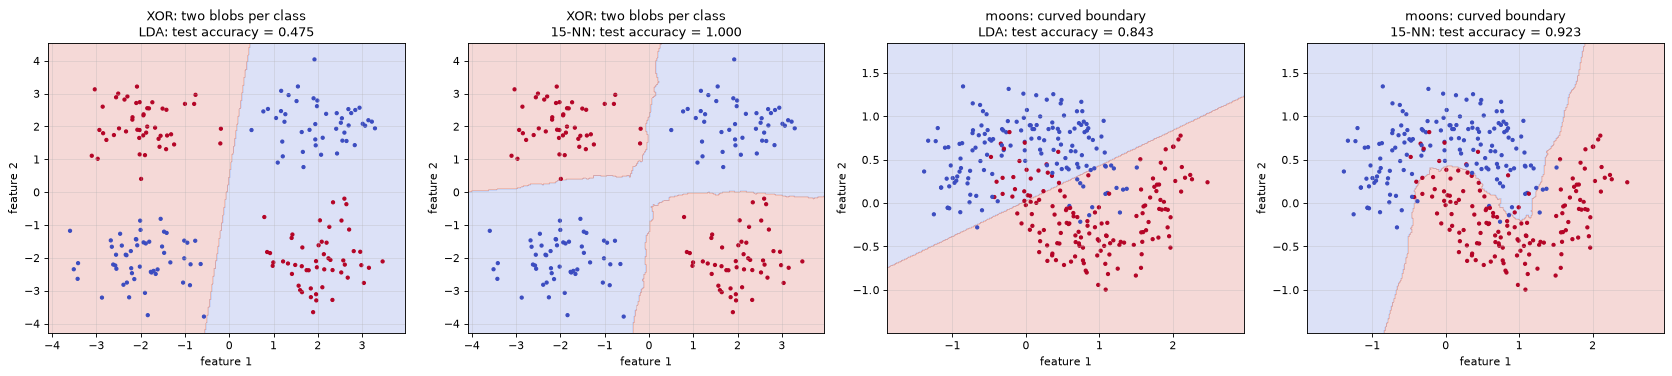

In [22]:
rng = np.random.default_rng(3)
corners = np.array([[-2, -2], [2, 2], [-2, 2], [2, -2]])            # class 0: first two, class 1: last two
X_xor = np.vstack([rng.normal(c, 0.7, size=(100, 2)) for c in corners])
y_xor = np.repeat([0, 0, 1, 1], 100)
X_moon, y_moon = make_moons(n_samples=600, noise=0.25, random_state=0)

gap_xor = X_xor[y_xor == 1].mean(axis=0) - X_xor[y_xor == 0].mean(axis=0)
Sw_x, Sb_x = scatter_matrices(X_xor, y_xor)
print(f"XOR: class means {X_xor[y_xor == 0].mean(axis=0)} and {X_xor[y_xor == 1].mean(axis=0)},"
      f" best possible Fisher ratio = {eigh(Sb_x, Sw_x, eigvals_only=True).max():.4f}")

fig, axes = plt.subplots(1, 4, figsize=(21, 4.8))
for col, (X, y, data_name) in enumerate([(X_xor, y_xor, "XOR: two blobs per class"),
                                         (X_moon, y_moon, "moons: curved boundary")]):
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.5, random_state=0, stratify=y)
    for j, (model, name) in enumerate([(LinearDiscriminantAnalysis(), "LDA"),
                                       (KNeighborsClassifier(n_neighbors=15), "15-NN")]):
        model.fit(X_tr, y_tr)
        ax = axes[2 * col + j]
        plot_regions(ax, model, X_te, y_te, f"{data_name}\n{name}: test accuracy = {model.score(X_te, y_te):.3f}")
        print(f"{data_name:26s} {name:6s}: test accuracy {model.score(X_te, y_te):.3f}")
plt.tight_layout(); plt.show()

> **How to read this**
> * **XOR:** the class means are $(0.014, 0.034)$ and $(-0.022, 0.074)$, practically the same point. The best possible
>   Fisher ratio is 0.0002, so LDA has nothing to work with: test accuracy **0.475** (coin flip). 15-NN gets **1.000**.
> * **Moons:** LDA's straight line gets the bulk right (0.843) but cuts through both tips. 15-NN follows the curve
>   (0.923).
> * Why: LDA only uses the class **means** and one shared **covariance**. If the classes differ in some other way (two
>   blobs per class, a curved shape), LDA cannot see it.
> * Fixes: k-NN, SVM with an RBF kernel, tree ensembles, neural networks; or a mixture model with several Gaussians
>   per class (mixture discriminant analysis). Kernel versions of LDA exist but are rarely used in practice.

## Lab 15 · Outliers drag the means and the covariance

**Goal:** LDA's ingredients — class means and the within-class covariance — are averages of (squared) distances, so a
few extreme points can move them a lot. We add 8 bad rows far away (labelled class 0) to 400 clean ones, then measure
the LDA direction and its accuracy on 4 000 new **clean** rows. The fix: flag rows that are far from their own class's
**robust** centre (Minimum Covariance Determinant, which ignores the most extreme points while estimating), drop them,
refit.

clean data                  : LDA direction θ = 149.3°, accuracy on 4000 new clean rows = 0.939
+ 8 outliers                : LDA direction θ =  15.8°, accuracy on 4000 new clean rows = 0.856
outliers flagged & removed  : LDA direction θ = 149.5°, accuracy on 4000 new clean rows = 0.939
rows removed by the robust check: 9 (of which outliers: 8)


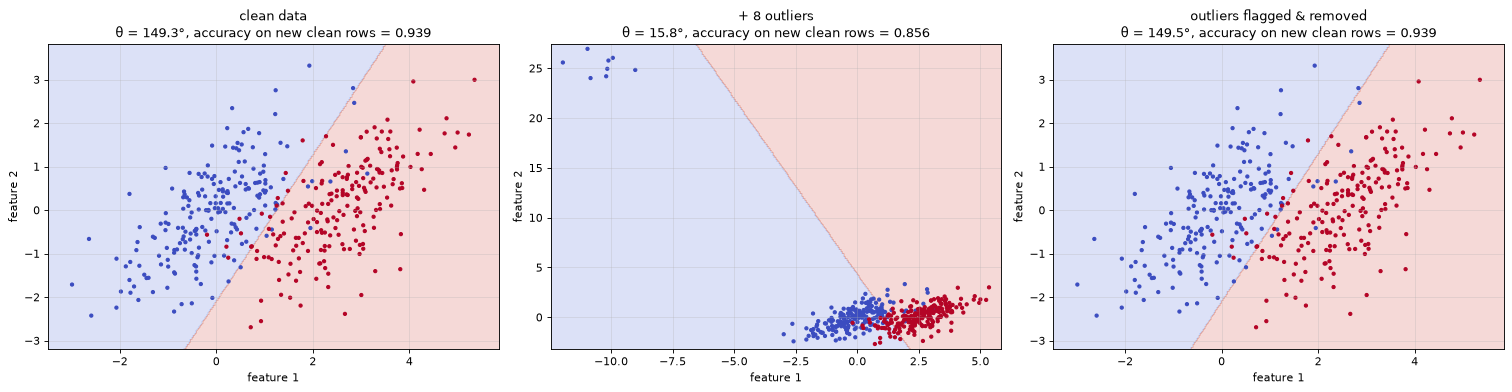

In [23]:
rng = np.random.default_rng(4)
cov_o = [[1.0, 0.6], [0.6, 1.0]]
X_clean = np.vstack([rng.multivariate_normal([0, 0], cov_o, 200), rng.multivariate_normal([2.5, 0], cov_o, 200)])
y_clean = np.repeat([0, 1], 200)
outliers = rng.normal([-10, 25], 1.0, size=(8, 2))           # 8 bad rows labelled class 0   <- try 0 or 20 rows
X_dirty = np.vstack([X_clean, outliers])
y_dirty = np.concatenate([y_clean, np.zeros(len(outliers), dtype=int)])
X_new = np.vstack([rng.multivariate_normal([0, 0], cov_o, 2000), rng.multivariate_normal([2.5, 0], cov_o, 2000)])
y_new = np.repeat([0, 1], 2000)

# Fix: flag rows that are far from their own class's robust centre (Minimum Covariance Determinant)
keep = np.ones(len(X_dirty), dtype=bool)
for k in (0, 1):
    rows = np.where(y_dirty == k)[0]
    robust = MinCovDet(random_state=0).fit(X_dirty[rows])
    keep[rows] = robust.mahalanobis(X_dirty[rows]) < chi2.ppf(0.999, df=2)

fits = {"clean data": (X_clean, y_clean), f"+ {len(outliers)} outliers": (X_dirty, y_dirty),
        "outliers flagged & removed": (X_dirty[keep], y_dirty[keep])}
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, (name, (X, y)) in zip(axes, fits.items()):
    lda = LinearDiscriminantAnalysis().fit(X, y)
    acc = lda.score(X_new, y_new)
    theta = angle_of(lda.coef_[0])
    print(f"{name:28s}: LDA direction θ = {theta:5.1f}°, accuracy on 4000 new clean rows = {acc:.3f}")
    plot_regions(ax, lda, X, y, f"{name}\nθ = {theta:.1f}°, accuracy on new clean rows = {acc:.3f}")
print(f"rows removed by the robust check: {np.sum(~keep)} (of which outliers: {np.sum(~keep[-len(outliers):])})")
plt.tight_layout(); plt.show()

> **How to read this**
> * **Clean data:** the LDA direction points at 149.3° and scores 0.939 on new clean rows.
> * **+ 8 outliers** (2 % of the rows): the direction swings to 15.8° and accuracy on clean data falls to 0.856. The
>   middle plot shows why: the 8 points (top left) drag class 0's mean and inflate the within-class covariance, so the
>   boundary tilts away from the real gap between the classes.
> * **Robust check:** 9 rows are flagged (all 8 outliers plus 1 genuine but unusual point). After removing them the
>   direction is back to 149.5° and accuracy to 0.939.
> * Fixes in practice: look at the data, remove or cap clear errors, use robust covariance estimates, or use a model
>   that is less sensitive to extreme points (tree models, for example).

## Lab 16 · Very imbalanced classes: the priors move the threshold

**Goal:** LDA learns the class **priors** (each class's share of the training data) and puts them into the
discriminant score ($\log \pi_k$ in Lab 5's proof). With 95 % vs 5 % that pushes the boundary deep into the minority
class. We compare the learned priors with equal priors (`priors=[0.5, 0.5]`) on a held-out test set, reporting
accuracy, **recall** of the minority class (the share of minority rows that were found) and **balanced accuracy**
(the average of the two classes' recalls).

learned priors (0.95 / 0.05)  : accuracy 0.961, minority recall 0.280, balanced accuracy 0.638
equal priors (0.5 / 0.5)      : accuracy 0.828, minority recall 0.840, balanced accuracy 0.834
|cos| between the two directions = 1.000000  (only the threshold moved)


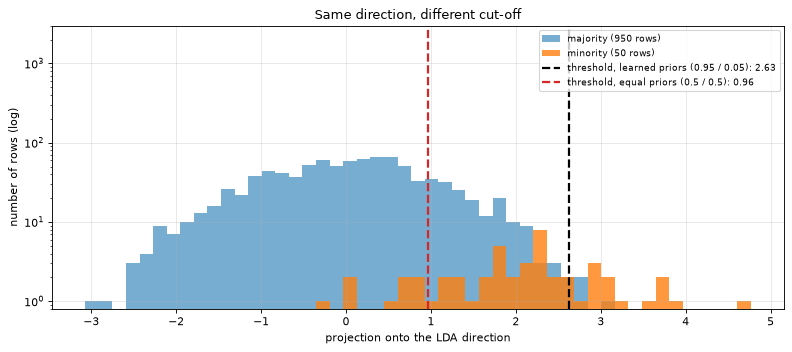

In [24]:
rng = np.random.default_rng(5)
n_major, n_minor = 1900, 100                                  # 95 % vs 5 %   <- try changing this
X_imb = np.vstack([rng.normal([0, 0], 1.0, (n_major, 2)), rng.normal([2, 0], 1.0, (n_minor, 2))])
y_imb = np.concatenate([np.zeros(n_major, dtype=int), np.ones(n_minor, dtype=int)])
X_tr, X_te, y_tr, y_te = train_test_split(X_imb, y_imb, test_size=0.5, random_state=0, stratify=y_imb)

fitted = {}
for name, priors in [("learned priors (0.95 / 0.05)", None), ("equal priors (0.5 / 0.5)", [0.5, 0.5])]:
    lda = LinearDiscriminantAnalysis(priors=priors).fit(X_tr, y_tr)
    pred = lda.predict(X_te)
    fitted[name] = lda
    print(f"{name:30s}: accuracy {accuracy_score(y_te, pred):.3f}, minority recall {recall_score(y_te, pred):.3f},"
          f" balanced accuracy {balanced_accuracy_score(y_te, pred):.3f}")
a, b = fitted.values()
print(f"|cos| between the two directions = {same_axis(a.coef_[0], b.coef_[0]):.6f}  (only the threshold moved)")

fig, ax = plt.subplots(figsize=(10, 4.5))
w_imb = a.coef_[0] / np.linalg.norm(a.coef_[0])
z = X_te @ w_imb
bins = np.linspace(z.min(), z.max(), 50)
ax.hist(z[y_te == 0], bins=bins, alpha=0.6, color="tab:blue", label=f"majority ({np.sum(y_te == 0)} rows)")
ax.hist(z[y_te == 1], bins=bins, alpha=0.8, color="tab:orange", label=f"minority ({np.sum(y_te == 1)} rows)")
for (name, lda), color in zip(fitted.items(), ["black", "tab:red"]):
    threshold = -lda.intercept_[0] / np.linalg.norm(lda.coef_[0])   # where coef·x + intercept = 0
    ax.axvline(threshold, color=color, ls="--", lw=2, label=f"threshold, {name}: {threshold:.2f}")
ax.set_yscale("log"); ax.set_ylim(0.8, 3000); ax.set_xlabel("projection onto the LDA direction"); ax.set_ylabel("number of rows (log)")
ax.set_title("Same direction, different cut-off"); ax.legend(fontsize=8, loc="upper right")
plt.tight_layout(); plt.show()

> **How to read this**
> * **Learned priors:** accuracy looks great (0.961), but only 28 % of the minority rows are found (recall 0.280);
>   balanced accuracy is 0.638. Saying “majority” almost always is the cheapest way to be right 95 % of the time.
> * **Equal priors:** accuracy drops to 0.828, but minority recall jumps to 0.840 and balanced accuracy to 0.834.
> * $|\cos| = 1.000000$: the **direction** is identical. Priors only move the cut-off along it, from 2.63 to 0.96 in
>   the histogram. (Note the log scale: the majority has 950 test rows, the minority 50.)
> * Which threshold is right depends on the cost of each mistake, not on the algorithm. Fixes: set `priors`, or keep
>   the default and pick a threshold on `predict_proba` that suits your costs; evaluate with balanced accuracy, recall
>   or precision–recall curves rather than plain accuracy.

---
# Summary — what each lab showed

| Lab | Claim from the README | Verdict |
|---|---|---|
| 1 | The hand-worked example: $w \propto (5, -1)$, $J = 3.5$ beats joining the means ($J = 2.885$) | ✔ same numbers |
| 2 | The direction with the best Fisher ratio is the top generalised eigenvector; the worst has $J = 0$ | ✔ brute force agrees |
| 3 | $\text{eig}(S_W^{-1}S_B)$ = `eigh(Sb, Sw)` = scikit-learn; scores uncorrelated within classes, axes not perpendicular | ✔ |
| 4 | At most C − 1 non-zero eigenvalues (digits: 9 of 61) | ✔ cliff after 9 |
| 5 | Shared-covariance Gaussians → linear boundary along Fisher's direction; that *is* `predict_proba` | ✔ to 1e-15 |
| 6 | PCA keeps variance, LDA keeps class separation | ✔ 0.490 vs 0.885 on one axis |
| 7 | LDA spreads labelled classes apart in a 2-D map | ✔ (but 2 axes are not enough for 10 classes) |
| 8 | LDA is a strong reducer down to C − 1 axes | ✔ wins at small k; PCA catches up by k = 9 |
| 9 | As a classifier LDA ≈ logistic regression; QDA needs far more data | ✔ |
| 10 | p > n − C breaks plain LDA; shrinkage fixes it | ✔ 0.667 vs 0.900 at p = 100 |
| 11 | Plain LDA ignores units; fixed shrinkage does not | ✔ 100 % vs 71.3 % same predictions |
| 12 | ✘ Fitting LDA before cross-validation leaks labels | failure shown (0.845 on pure noise) |
| 13 | ✘ Different class shapes → LDA's straight line is wrong; use QDA | failure shown |
| 14 | ✘ Multimodal classes / curved boundaries → LDA can't see them | failure shown |
| 15 | ✘ A few outliers rotate the direction | failure shown (and fixed) |
| 16 | ✘ Imbalanced priors push the threshold into the minority class | failure shown (and fixed) |

---
# Beyond the labs: when to use LDA

The labs show what LDA does. Whether it is the right tool depends on your data and your goal.

**LDA is a good choice**

| Situation | Why |
|---|---|
| **Small or medium tabular data whose classes look like similar-shaped blobs** (iris, wine, many lab measurements) | LDA's assumption roughly holds, so it is about as accurate as anything (Lab 9: 0.980 on iris, 0.994 on wine), trains in one pass and has no hyper-parameters to tune. |
| **Few rows, many features** (genomics, spectroscopy, EEG / brain–computer interfaces) — **with shrinkage** | Shrinkage LDA is a standard method in EEG classification precisely because it stays stable when p is close to or above n. (The stability is shown in Lab 10; the EEG practice is from the literature, not tested here.) |
| **A fast, honest baseline** | Closed-form fit, probabilities included, nothing to tune. If a fancy model can't beat LDA, the fancy model isn't earning its keep. |
| **Supervised dimensionality reduction before a distance-based model** (k-NN, clustering for exploration) | Up to C − 1 axes that keep class separation, so fewer, better features for the next step (Labs 6–8). |
| **Visualising labelled data** | A 2-D LDA map spreads the classes apart, where a PCA map spreads whatever varies most (Labs 6–7). |
| **Face recognition and other image-ID problems (“Fisherfaces”)** | Classic recipe: PCA first (to get below n features, so $S_W$ is invertible), then LDA to separate the people. (From the literature; not tested here.) |
| **You need an interpretable linear model with probabilities** | Each class score is a linear function of the features; the coefficients can be read like logistic regression's. |

**Use something else**

| Situation | Use instead | Why |
|---|---|---|
| Classes have clearly different spreads or tilts | QDA, regularised QDA, Gaussian naive Bayes | LDA's one shared covariance can't express it (Lab 13). |
| Curved boundaries, several clusters per class | k-NN, SVM with RBF kernel, gradient boosting / random forest, neural networks | LDA only sees class means and one covariance (Lab 14). |
| Large data, skewed / non-Gaussian / one-hot features | Logistic regression, gradient boosting | Logistic regression makes no assumption about how the features are distributed (Lab 9: breast_cancer, digits). |
| Outliers or data-entry errors | Clean the data first; robust covariance; tree models | Means and covariances are pulled by extreme points (Lab 15). |
| The minority class matters most | LDA with `priors` set or a tuned threshold, judged by recall / balanced accuracy | Default priors favour the majority (Lab 16). |
| No labels at all | PCA, UMAP / t-SNE, clustering | LDA needs `y`; it cannot find groups you haven't labelled. |
| You want more than C − 1 new features | PCA, PLS, feature selection | LDA gives at most C − 1 axes (Lab 4). |
| Tree models downstream | Usually skip it | Trees pick their own splits on original columns; blended columns tend to make worse splits (the PCA lab's Lab 16 tests this for PCA; it was not tested here for LDA). |

**Rule of thumb**

* Reach for LDA when the classes are **roughly Gaussian, similarly shaped, and the number of rows per class is
  limited** — add `shrinkage="auto"` (with `solver="lsqr"` or `"eigen"`) whenever features are many relative to rows.
* Use it as a reducer when you want **at most C − 1 features that keep the classes apart**, and always fit it inside a
  `Pipeline` (Lab 12).
* Check the assumption cheaply: compare LDA with QDA and logistic regression by cross-validation (Lab 9). If QDA wins
  clearly, the class shapes differ; if logistic regression wins clearly, the features are far from Gaussian.